# Assignment 2: Embeddings and Hidden Markov Models

Natural Language Processing, Alexandria University, Computer and Systems Department

This notebook follows the three parts of the assignment:

1. **Part 1**: sparse (PMI, TF-IDF) and dense (Word2Vec) word representations, all written from scratch.
2. **Part 2**: an HMM part-of-speech tagger with Viterbi decoding.
3. **Part 3**: an HMM whose unknown-word emissions are informed by the three representations of Part 1.

Only Python and NumPy are used for the models. The `datasets` library is used just to download CoNLL-2000 and matplotlib just for plots.

**Tuned on the validation split:** vocabulary size (min-count sweep, HMM criterion), Word2Vec learning rate x learning-rate decay (3x3 grid), embedding dimension, number of negatives and context window; the number of epochs (early stopping, patience 2); PMI window and context smoothing; HMM smoothing and unknown-word threshold; and the integration parameters k, tau, beta, epsilon of Part 3.
**Fixed, with a justification (see 1.4):** Word2Vec batch size (256), noise-distribution exponent (0.75), early-stopping patience (2), maximum epochs (20) and the neighbour cap `K_MAX`. The final report lists every setting and whether it was tuned or fixed.

**Use of the test set.** The test set is used for (i) unknown-word statistics in Section 1.1, (ii) the baseline HMM evaluation in Section 2.3, whose predictions are reused in Part 3, and (iii) the final comparison of the four systems in Section 3.3. No hyperparameter is chosen with it: every selection uses the validation split only.

## 0. Setup and data

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from datasets import load_dataset

SEED = 42

In [2]:
try:
    raw = load_dataset("eriktks/conll2000")
except Exception:
    # newer versions of `datasets` cannot run dataset scripts, so fall back to the parquet conversion
    raw = load_dataset("eriktks/conll2000", revision="refs/convert/parquet")

tag_names = raw["train"].features["pos_tags"].feature.names
n_tags = len(tag_names)
print("train sentences:", len(raw["train"]), "| test sentences:", len(raw["test"]), "| pos tags:", n_tags)

train sentences: 8936 | test sentences: 2012 | pos tags: 45


**Split.** The original training partition is shuffled once with a fixed seed and 10% of it becomes the validation set.
The original test partition is kept aside. Only `tokens` and `pos_tags` are used (no chunk labels).

In [3]:
all_tokens = raw["train"]["tokens"]
all_tags = raw["train"]["pos_tags"]

rng = np.random.RandomState(SEED)
perm = rng.permutation(len(all_tokens))
n_val = int(0.1 * len(perm))
val_idx, train_idx = perm[:n_val], perm[n_val:]

train_tokens = [all_tokens[i] for i in train_idx]
val_tokens = [all_tokens[i] for i in val_idx]
test_tokens = raw["test"]["tokens"]

train_tags = [np.array(all_tags[i]) for i in train_idx]
val_tags = [np.array(all_tags[i]) for i in val_idx]
test_tags = [np.array(t) for t in raw["test"]["pos_tags"]]

print("train / validation / test sentences:", len(train_tokens), len(val_tokens), len(test_tokens))

train / validation / test sentences: 8043 893 2012


## Part 1: Sparse and dense word representations

### 1.1 Preprocessing and vocabulary

Preprocessing choices:

* **Lowercasing.** `The` and `the` should share one vector, and lowercasing makes the counts less sparse. The price is that capitalisation (a strong hint for proper nouns) is lost. All systems below see the same lowercased text, so the comparison stays fair. A validation-only ablation of this choice (cased vs lowercased, with the real vocabulary sizes and `NNP` F1) is run in Section 2.1, after the HMM settings are tuned.
* **Numbers become `<num>`.** Every token containing a digit (`1989`, `3.5`, `10-year`) is replaced by one symbol. There are endless distinct numbers, but they all behave the same way, so this stops them from being unknown words.
* **Punctuation is kept.** Punctuation tokens have their own POS tags (`,` `.` `$` ...), and the HMM needs them.
* **No stemming, no stop-word removal.** Function words are exactly what determines POS tags.

**Vocabulary.** Built from the training split only. The default keeps every training word (`min_count = 1`), so the vocabulary size is the number of distinct training words. This choice is checked with the min-count sweep below. `unk_max` in Section 2.1 acts as the effective vocabulary/OOV cut-off inside the HMM.

In [4]:
def clean(tok):
    tok = tok.lower()
    if any(ch.isdigit() for ch in tok):
        return "<num>"
    return tok

train_words = [[clean(t) for t in s] for s in train_tokens]
val_words = [[clean(t) for t in s] for s in val_tokens]
test_words = [[clean(t) for t in s] for s in test_tokens]

word_count = Counter(w for s in train_words for w in s)
word2id = {w: i for i, (w, _) in enumerate(word_count.most_common())}
id2word = {i: w for w, i in word2id.items()}
V = len(word2id)
UNK = V

def encode(sents):
    return [np.array([word2id.get(w, UNK) for w in s]) for s in sents]

train_ids, val_ids, test_ids = encode(train_words), encode(val_words), encode(test_words)

n_train_tok = sum(len(s) for s in train_ids)
print("vocabulary size V:", V, "| training tokens:", n_train_tok)
print("words seen once in training:", sum(1 for c in word_count.values() if c == 1))
for name, ids in [("validation", val_ids), ("test", test_ids)]:
    flat = np.concatenate(ids)
    print(f"{name}: {len(flat)} tokens, unknown-word rate {np.mean(flat == UNK):.2%} ({np.sum(flat == UNK)} tokens)")

vocabulary size V: 14622 | training tokens: 190794
words seen once in training: 6767
validation: 20933 tokens, unknown-word rate 3.28% (687 tokens)
test: 47377 tokens, unknown-word rate 5.84% (2766 tokens)


> **Validation vs. test unknown-word rate.** The unknown-word rate of the validation split is clearly lower than that of the test split (numbers printed above). With so few unknown validation tokens, tuning the integration hyperparameters ($k, \tau, \beta, \varepsilon$) has a high sampling variance, and values that are optimal on validation may be slightly mis-calibrated for the higher unknown-word density of the test set.

**Vocabulary size (min-count) sweep.** Words seen only once in training contribute noisy vectors to PMI and Word2Vec. We sweep `min_count` $\in \{1, 2, 3, 5\}$ and score a small HMM (trained on the train split) on validation accuracy to see whether pruning infrequent words helps. The HMM is the criterion here; PMI and Word2Vec are not re-optimised for every vocabulary size (see the limitations at the end). The self-contained function below is also reused for the lowercasing ablation in Section 2.1.

In [5]:
def f1_of_tag(gold, pred, tag):
    tp = np.sum((gold == tag) & (pred == tag)); fp = np.sum((gold != tag) & (pred == tag)); fn = np.sum((gold == tag) & (pred != tag))
    return 0.0 if tp == 0 else 2 * tp / (2 * tp + fp + fn)

def hmm_eval_generic(tr_words, vl_words, min_c=1, a_t=1.0, a_e=0.01, unk_max=3):
    # Self-contained HMM (trained on the train split, scored on the validation split only).
    # Used for the vocabulary-size sweep and for the lowercasing ablation.
    wc = Counter(w for s in tr_words for w in s)
    kept = sorted(((w, c) for w, c in wc.items() if c >= min_c), key=lambda x: (-x[1], x[0]))
    w2i = {w: i for i, (w, _) in enumerate(kept)}
    V_c = len(w2i); UNK_c = V_c
    tr = [np.array([w2i.get(w, UNK_c) for w in s]) for s in tr_words]
    vl = [np.array([w2i.get(w, UNK_c) for w in s]) for s in vl_words]
    init = np.zeros(n_tags); trans = np.zeros((n_tags, n_tags)); emit = np.zeros((n_tags, V_c + 1))
    for ids, tags in zip(tr, train_tags):
        init[tags[0]] += 1
        np.add.at(trans, (tags[:-1], tags[1:]), 1)
        np.add.at(emit, (tags, ids), 1)          # words pruned by min_c already land in the UNK column
    freq = emit[:, :V_c].sum(0)
    rare = (freq > 0) & (freq <= unk_max)
    emit[:, V_c] += emit[:, :V_c][:, rare].sum(1)   # rare kept words are extra examples of unknown words
    log_pi = np.log((init + a_t) / (init.sum() + a_t * n_tags))
    log_A = np.log((trans + a_t) / (trans.sum(1, keepdims=True) + a_t * n_tags))
    log_B = np.log((emit + a_e) / (emit.sum(1, keepdims=True) + a_e * (V_c + 1)))   # every row sums to 1
    preds = []
    for ids in vl:
        n = len(ids); log_emit = log_B[:, ids].T
        delta = log_pi + log_emit[0]
        back = np.zeros((n, n_tags), dtype=int)
        for t in range(1, n):
            sc = delta[:, None] + log_A
            back[t] = sc.argmax(axis=0)
            delta = sc.max(axis=0) + log_emit[t]
        path = [int(delta.argmax())]
        for t in range(n - 1, 0, -1):
            path.append(int(back[t][path[-1]]))
        preds.append(np.array(path[::-1]))
    p = np.concatenate(preds); g = np.concatenate(val_tags)
    unk_m = np.concatenate(vl) == V_c
    return dict(V=V_c, acc=(p == g).mean(), unk_acc=(p[unk_m] == g[unk_m]).mean(), oov=unk_m.mean(), pred=p, gold=g)

# Vocabulary size (min-count) sweep on the validation split (train + validation only)
print(f"{'min_count':>10} {'vocab_size':>12} {'val_acc':>10} {'val_unk_acc':>14} {'val_oov_rate':>14}")
mc_results = {}
for mc in [1, 2, 3, 5]:
    r_ = hmm_eval_generic(train_words, val_words, min_c=mc)
    mc_results[mc] = r_
    print(f"{mc:>10d} {r_['V']:>12d} {r_['acc']:>10.4f} {r_['unk_acc']:>14.4f} {r_['oov']:>14.2%}")

best_mc = max(mc_results, key=lambda m: mc_results[m]["acc"])
spread = max(r_["acc"] for r_ in mc_results.values()) - min(r_["acc"] for r_ in mc_results.values())
print(f"\n-> best min_count by validation accuracy: {best_mc} (acc {mc_results[best_mc]['acc']:.4f}); spread across the four settings: {spread:.4f}")
print(f"-> min_count=1 gives {mc_results[1]['acc']:.4f}, which is {mc_results[best_mc]['acc'] - mc_results[1]['acc']:.4f} below the best")

 min_count   vocab_size    val_acc    val_unk_acc   val_oov_rate


         1        14622     0.9470         0.5357          3.28%


         2         7855     0.9379         0.5271          5.56%


         3         5602     0.9298         0.5222          7.43%


         5         3696     0.9146         0.4977         10.28%

-> best min_count by validation accuracy: 1 (acc 0.9470); spread across the four settings: 0.0324
-> min_count=1 gives 0.9470, which is 0.0000 below the best


Both sparse representations store one sparse row per word. A row is just a pair of NumPy arrays (column indices, values), kept in a Python list indexed by word id.
To compare many words with all rows without ever building the full dense matrix, `sparse_cosine` expands a block of rows at a time into a small dense array and multiplies.

In [6]:
def sparse_cosine(queries, rows, dim, block=1500):
    # queries: dense (n, dim); rows: list of (cols, vals), one per word. returns cosine (n, len(rows))
    q = queries / np.maximum(np.linalg.norm(queries, axis=1, keepdims=True), 1e-9)
    q = q.astype(np.float32)
    out = np.zeros((len(queries), len(rows)), dtype=np.float32)
    for start in range(0, len(rows), block):
        end = min(start + block, len(rows))
        chunk = np.zeros((end - start, dim), dtype=np.float32)
        for j in range(start, end):
            cols, vals = rows[j]
            chunk[j - start, cols] = vals
        norms = np.maximum(np.linalg.norm(chunk, axis=1), 1e-9)
        out[:, start:end] = (q @ chunk.T) / norms
    return out

def top_k(scores, k):
    idx = np.argpartition(-scores, k, axis=1)[:, :k]
    vals = np.take_along_axis(scores, idx, 1)
    order = np.argsort(-vals, axis=1)
    return np.take_along_axis(idx, order, 1), np.take_along_axis(vals, order, 1)

def dense_row(row, dim):
    v = np.zeros(dim, dtype=np.float32)
    v[row[0]] = row[1]
    return v

### 1.2 PMI

The word-context matrix counts how often context word $c$ appears within $\pm w$ tokens of word $x$ (inside the same sentence). Then

$$\mathrm{PMI}(x,c)=\log\frac{P(x,c)}{P(x)\,P_\alpha(c)},\qquad P_\alpha(c)=\frac{\#(c)^{\alpha}}{\sum_{c'}\#(c')^{\alpha}}$$

$\alpha=0.75$ (context smoothing) lowers the PMI of very rare contexts, which otherwise get inflated values.
Only pairs that were actually seen are stored, and negative PMI is clipped to zero (positive PMI, PPMI). Unseen pairs would have $-\infty$ PMI, and negative values from small counts are mostly noise, so keeping only positive values is the usual choice. It is also what makes the matrix sparse.

The window size `PMI_WINDOW` and $\alpha$ are tuned in section 3.2 on the validation set, because their effect can only be judged on the downstream task. The values set here are only the starting configuration for Part 1; the validation search in section 3.2 selects the final window and $\alpha$ and *applies* them (the PMI rows are rebuilt if they differ).

In [7]:
PMI_WINDOW = 2   # starting configuration, replaced by the validated choice of section 3.2
PMI_ALPHA = 0.75

def cooccurrence(ids_list, window):
    keys = []
    for ids in ids_list:
        for d in range(1, window + 1):
            if len(ids) > d:
                keys.append(ids[:-d].astype(np.int64) * V + ids[d:])
                keys.append(ids[d:].astype(np.int64) * V + ids[:-d])
    pair_ids, counts = np.unique(np.concatenate(keys), return_counts=True)
    return pair_ids // V, pair_ids % V, counts

def ppmi_rows(w, c, counts, alpha):
    total = counts.sum()
    word_tot = np.bincount(w, weights=counts, minlength=V)
    ctx_tot = np.bincount(c, weights=counts, minlength=V) ** alpha
    ctx_prob = ctx_tot / ctx_tot.sum()
    pmi = np.log((counts / total) / ((word_tot[w] / total) * ctx_prob[c]))
    keep = pmi > 0
    w, c, pmi = w[keep], c[keep], pmi[keep].astype(np.float32)
    bounds = np.searchsorted(w, np.arange(V + 1))
    rows = [(c[bounds[i]:bounds[i + 1]], pmi[bounds[i]:bounds[i + 1]]) for i in range(V)]
    return rows, ctx_prob

co_w, co_c, co_n = cooccurrence(train_ids, PMI_WINDOW)
pmi_rows, pmi_ctx_prob = ppmi_rows(co_w, co_c, co_n, PMI_ALPHA)
PMI_BUILT = (PMI_WINDOW, PMI_ALPHA)   # configuration that the current pmi_rows were built with

nnz_pmi = sum(len(r[0]) for r in pmi_rows)
print("distinct co-occurring (word, context) pairs:", len(co_n))
print("non-zero PPMI entries:", nnz_pmi, f"({nnz_pmi / V ** 2:.3%} of the {V} x {V} matrix)")

distinct co-occurring (word, context) pairs: 322441
non-zero PPMI entries: 301215 (0.141% of the 14622 x 14622 matrix)


**PMI versus raw counts.** Raw counts are dominated by frequent words: the top contexts of almost any word are `the`, `,` and `.`, which say nothing about the word.
PMI divides by the context probability, so a context counts only if it appears with the word more often than chance. Below, for a few words, the strongest contexts by raw count and by PPMI.

In [8]:
def show_contexts(word, n=8):
    i = word2id[word]
    mine = co_w == i
    ctx, cnt = co_c[mine], co_n[mine]
    by_count = ctx[np.argsort(-cnt)[:n]]
    cols, vals = pmi_rows[i]
    by_pmi = cols[np.argsort(-vals)[:n]]
    print(f"{word}")
    print("   raw count:", [id2word[j] for j in by_count])
    print("   PPMI     :", [id2word[j] for j in by_pmi])

for w in ["company", "said", "market"]:
    show_contexts(w)

company
   raw count: ['the', ',', "'s", 'said', 'a', '.', 'to', 'of']
   PPMI     : ['phoenix-based', 'health-care-product', 'flagship', 'third-period', 'supplied', 'calif.-based', 'laden', 'midwestern']
said
   raw count: [',', 'the', '.', 'it', "''", 'he', 'mr.', 'company']
   PPMI     : ['hoechst', 'knowledgeable', 'spokesman', 'sri', 'oriani', 'dillow', 'prideaux', 'fitzwater']
market
   raw count: ['the', ',', '.', 'stock', 'a', "'s", 'to', 'of']
   PPMI     : ['unification', 'barometer', 'strategist', 'bull', 'booming', 'glutted', 'psychologically', 'private-line']


### 1.3 TF-IDF

Every training sentence is a document. The entry for word $x$ in document $d$ is $\mathrm{tf}(x,d)\cdot\mathrm{idf}(x)$ with $\mathrm{tf}$ the raw count of $x$ in $d$ and $\mathrm{idf}(x)=\log(N/\mathrm{df}(x))$, where $N$ is the number of sentences and $\mathrm{df}$ the number of sentences containing $x$.
The vector of a word is its row over all sentences (dimension $N$), stored sparsely like the PPMI rows. Two words are similar if they tend to appear in the same sentences (cosine of their rows).

Note that idf is a constant factor on each row, so it cancels in the cosine between two known words. It only matters later, when rows of different words are added together (section 3.1).

In [9]:
def build_tfidf(ids_list):
    n_docs = len(ids_list)
    per_word = [dict() for _ in range(V)]
    for d, ids in enumerate(ids_list):
        words, counts = np.unique(ids, return_counts=True)
        for w, c in zip(words, counts):
            per_word[w][d] = c
    idf = np.log(n_docs / np.array([len(p) for p in per_word]))
    rows = []
    for w in range(V):
        docs = np.array(list(per_word[w].keys()))
        tf = np.array(list(per_word[w].values()), dtype=np.float32)
        rows.append((docs, tf * idf[w]))
    return rows, idf

n_docs = len(train_ids)
tfidf_rows, idf = build_tfidf(train_ids)

nnz_tfidf = sum(len(r[0]) for r in tfidf_rows)
print("documents (sentences):", n_docs)
print("non-zero TF-IDF entries:", nnz_tfidf, f"({nnz_tfidf / (V * n_docs):.3%} of the {V} x {n_docs} matrix)")

documents (sentences): 8043
non-zero TF-IDF entries: 167554 (0.142% of the 14622 x 8043 matrix)


### 1.4 Word2Vec (skip-gram with negative sampling)

Every word has two vectors: an input vector $v_w$ (rows of `W_in`) and an output vector $u_w$ (rows of `W_out`).
For a (center $w$, context $o$) pair and $K$ negative words $n_1..n_K$ drawn from the unigram distribution raised to the power 0.75, the loss is

$$L=-\log\sigma(u_o^\top v_w)-\sum_{k=1}^{K}\log\sigma(-u_{n_k}^\top v_w)$$

**Gradients** (using $\sigma'(x)=\sigma(x)(1-\sigma(x))$ and $\frac{d}{dx}[-\log\sigma(x)]=\sigma(x)-1$):

$$\frac{\partial L}{\partial u_o}=(\sigma(u_o^\top v_w)-1)\,v_w,\qquad
\frac{\partial L}{\partial u_{n_k}}=\sigma(u_{n_k}^\top v_w)\,v_w$$

$$\frac{\partial L}{\partial v_w}=(\sigma(u_o^\top v_w)-1)\,u_o+\sum_{k=1}^{K}\sigma(u_{n_k}^\top v_w)\,u_{n_k}$$

**Derivation via Chain Rule:**
For a positive pair $(w, o)$ and $K$ negative samples $\{n_k\}$, let $z_o = u_o^\top v_w$ and $z_{n_k} = -u_{n_k}^\top v_w$. Using $\frac{d}{dz}[-\log\sigma(z)] = \sigma(z) - 1$ and $\sigma(-z) = 1 - \sigma(z)$:

1. **Positive output vector $u_o$**:
$$\frac{\partial L}{\partial u_o} = \frac{d [-\log\sigma(z_o)]}{d z_o} \cdot \frac{\partial z_o}{\partial u_o} = (\sigma(u_o^\top v_w) - 1)\,v_w$$

2. **Negative output vector $u_{n_k}$**:
$$\frac{\partial L}{\partial u_{n_k}} = \frac{d [-\log\sigma(z_{n_k})]}{d z_{n_k}} \cdot \frac{\partial z_{n_k}}{\partial u_{n_k}} = (\sigma(-u_{n_k}^\top v_w) - 1)(-v_w) = (1 - \sigma(-u_{n_k}^\top v_w))\,v_w = \sigma(u_{n_k}^\top v_w)\,v_w$$

3. **Center input vector $v_w$** (summing chain-rule contributions from positive and all $K$ negative terms):
$$\frac{\partial L}{\partial v_w} = (\sigma(u_o^\top v_w) - 1)\,u_o + \sum_{k=1}^{K}\sigma(u_{n_k}^\top v_w)\,u_{n_k}$$

The update is gradient descent, $\theta\leftarrow\theta-\eta\,\partial L/\partial\theta$, done by hand in NumPy. There is no autograd and no optimizer. The learning rate is multiplied by `decay` after every epoch, and `decay` is tuned together with the initial learning rate.

**Batch update (what the code does).** For speed, 256 (center, context) pairs are processed together:

1. forward and backward are computed for all 256 pairs with the weights *from before* the batch update (one function, `sgns_grads`, used by training and by the gradient check below);
2. the per-pair gradients are **summed**: if one word appears several times in the batch, the gradients of its rows are added (`scatter_add`);
3. one update is applied for the batch: $\theta\leftarrow\theta-\eta\sum_{\text{pairs}}\partial L_{\text{pair}}/\partial\theta$.

So the batch objective is the *sum* of the 256 per-pair losses and $\eta$ is a per-pair step size (it is not divided by the batch size). This is a mini-batch update, not sequential per-pair SGD. The training loss shown in the curves is the *mean* per pair, which is only a reporting convention.
$W_{in}$ is initialised uniformly in $[-0.5/d, 0.5/d]$ and $W_{out}$ with zeros, as in the original word2vec.

**Validation.** The validation loss is the same SGNS loss on (center, context) pairs from the validation sentences, with a fixed set of 5 negatives per pair so that runs with different $K$ can be compared.
After every epoch the validation loss is measured. Training stops when it has not improved for `patience = 2` consecutive epochs (or after `max_epochs = 20`), and the weights of the best epoch are restored and returned (early stopping, so the number of epochs is selected automatically).

**Fixed choices.** *Batch size 256* is an implementation choice for NumPy speed; because gradients are summed and the learning rates searched are at most 0.1, training was stable at this size. *Noise exponent 0.75* is the standard word2vec value. It is not tuned here on purpose: the validation loss is measured on negatives drawn from the same noise distribution, so it cannot compare different exponents fairly, and a fair comparison would need a downstream criterion for every exponent, which is too expensive for this assignment.

In [10]:
def make_pairs(ids_list, window):
    centers, contexts = [], []
    for ids in ids_list:
        for d in range(1, window + 1):
            if len(ids) > d:
                centers += [ids[:-d], ids[d:]]
                contexts += [ids[d:], ids[:-d]]
    return np.concatenate(centers), np.concatenate(contexts)

def sigmoid(x):
    return 1.0 / (1.0 + np.exp(-np.clip(x, -30, 30)))

unigram = np.bincount(np.concatenate(train_ids), minlength=V) ** 0.75
noise_cdf = np.cumsum(unigram / unigram.sum())

def sample_negatives(r, shape):
    return np.searchsorted(noise_cdf, r.random(shape))

def scatter_add(W, idx, grad):
    # W[idx] -= grad, but rows that occur several times in idx get the sum of their gradients
    order = np.argsort(idx, kind="stable")
    sorted_idx = idx[order]
    starts = np.flatnonzero(np.r_[True, sorted_idx[1:] != sorted_idx[:-1]])
    W[sorted_idx[starts]] -= np.add.reduceat(grad[order], starts, axis=0)

def sgns_loss(W_in, W_out, centers, contexts, negatives):
    v = W_in[centers]
    pos = sigmoid((v * W_out[contexts]).sum(1))
    neg = sigmoid(np.einsum("bd,bkd->bk", v, W_out[negatives]))
    return (-np.log(pos + 1e-10) - np.log(1 - neg + 1e-10).sum(1)).mean()

def sgns_forward(v, u_pos, u_neg):
    # v: (B, d) center vectors, u_pos: (B, d) positive output vectors, u_neg: (B, K, d) negative output vectors
    s_pos = sigmoid((v * u_pos).sum(1))
    s_neg = sigmoid(np.einsum("bd,bkd->bk", v, u_neg))
    return s_pos, s_neg

def sgns_pair_loss(s_pos, s_neg):
    # per-pair loss  -log s_pos - sum_k log(1 - s_neg_k)   (the 1e-10 only protects the log)
    return -np.log(s_pos + 1e-10) - np.log(1 - s_neg + 1e-10).sum(1)

def sgns_grads(v, u_pos, u_neg):
    # Analytical gradients of the per-pair loss with respect to the three groups of vectors.
    # One function, used by the training loop AND by the finite-difference check below.
    s_pos, s_neg = sgns_forward(v, u_pos, u_neg)
    g_pos = (s_pos - 1)[:, None]
    grad_v = g_pos * u_pos + np.einsum("bk,bkd->bd", s_neg, u_neg)
    grad_u_pos = g_pos * v
    grad_u_neg = s_neg[:, :, None] * v[:, None, :]
    return s_pos, s_neg, grad_v, grad_u_pos, grad_u_neg

def make_val_set(window, n_neg=5):
    c, o = make_pairs(val_ids, window)
    ok = (c < V) & (o < V)          # pairs that contain an unknown word are skipped
    c, o = c[ok], o[ok]
    neg = sample_negatives(np.random.RandomState(1), (len(c), n_neg))
    return c, o, neg

In [11]:
def train_w2v(window, dim, n_neg, lr0, decay=0.7, max_epochs=20, batch=256, patience=2, seed=0, verbose=False):
    r = np.random.RandomState(seed)
    W_in = r.uniform(-0.5 / dim, 0.5 / dim, (V, dim))
    W_out = np.zeros((V, dim))
    centers, contexts = make_pairs(train_ids, window)
    val_set = make_val_set(window)
    n = len(centers)

    best = {"val": np.inf, "epoch": 0, "W_in": None, "W_out": None}
    hist = {"train": [], "val": []}
    bad = 0                                   # epochs in a row without improvement of the validation loss
    for epoch in range(1, max_epochs + 1):
        t0 = time.time()
        lr = lr0 * decay ** (epoch - 1)
        order = r.permutation(n)
        total = 0.0
        for s in range(0, n, batch):
            b = order[s:s + batch]
            c, o = centers[b], contexts[b]
            neg = sample_negatives(r, (len(b), n_neg))

            # forward + backward with the weights from before this batch update
            v, u_pos, u_neg = W_in[c], W_out[o], W_out[neg]
            s_pos, s_neg, grad_v, grad_u_pos, grad_u_neg = sgns_grads(v, u_pos, u_neg)
            total += sgns_pair_loss(s_pos, s_neg).sum()

            # update: gradients of repeated rows are summed, one step per batch
            scatter_add(W_out, o, lr * grad_u_pos)
            scatter_add(W_out, neg.ravel(), lr * grad_u_neg.reshape(-1, dim))
            scatter_add(W_in, c, lr * grad_v)

        hist["train"].append(total / n)
        hist["val"].append(sgns_loss(W_in, W_out, *val_set))
        if verbose:
            print(f"  epoch {epoch:2d}  train loss {hist['train'][-1]:.4f}  val loss {hist['val'][-1]:.4f}  ({time.time() - t0:.0f}s)")
        if hist["val"][-1] < best["val"]:
            best = {"val": hist["val"][-1], "epoch": epoch, "W_in": W_in.copy(), "W_out": W_out.copy()}
            bad = 0
        else:
            bad += 1
            if bad >= patience:
                break
    return best, hist      # the weights of the best epoch, not of the last one

**Gradient check.** The analytical gradients of `sgns_grads` (the same function the training loop calls) are compared with central finite differences, $\frac{L(\theta+h)-L(\theta-h)}{2h}$, on a small random example in float64. The relative error is $\lVert g_{ana}-g_{num}\rVert/(\lVert g_{ana}\rVert+\lVert g_{num}\rVert)$. The check also verifies that `scatter_add` is exactly the sum of the per-pair updates.

In [12]:
def grad_check(B=4, K=5, dim=8, h=1e-6, seed=123):
    r = np.random.RandomState(seed)
    params = {"v": r.randn(B, dim), "u_pos": r.randn(B, dim), "u_neg": r.randn(B, K, dim)}
    _, _, g_v, g_up, g_un = sgns_grads(params["v"], params["u_pos"], params["u_neg"])
    ana = {"v": g_v, "u_pos": g_up, "u_neg": g_un}

    def total_loss():
        return sgns_pair_loss(*sgns_forward(params["v"], params["u_pos"], params["u_neg"])).sum()

    worst = 0.0
    for name, arr in params.items():
        num = np.zeros_like(arr)
        for idx in np.ndindex(arr.shape):
            keep_ = arr[idx]
            arr[idx] = keep_ + h; lp = total_loss()
            arr[idx] = keep_ - h; lm = total_loss()
            arr[idx] = keep_
            num[idx] = (lp - lm) / (2 * h)
        rel = np.linalg.norm(ana[name] - num) / (np.linalg.norm(ana[name]) + np.linalg.norm(num) + 1e-12)
        print(f"gradient wrt {name:6s}: relative error {rel:.2e}")
        worst = max(worst, rel)
    return worst

worst_rel_err = grad_check()
assert worst_rel_err < 1e-6, "analytical gradients do not match finite differences"
print(f"gradient check passed (worst relative error {worst_rel_err:.2e} < 1e-6)")

# scatter_add must equal the sum of the individual per-pair updates
r_ = np.random.RandomState(0)
W_t = r_.randn(6, 3); idx_t = np.array([1, 1, 4, 1]); g_t = r_.randn(4, 3)
W_ref = W_t.copy()
for i_, gi in zip(idx_t, g_t):
    W_ref[i_] -= gi
W_chk = W_t.copy(); scatter_add(W_chk, idx_t, g_t)
assert np.allclose(W_ref, W_chk)
print("scatter_add equals the sum of the per-pair updates: True")

gradient wrt v     : relative error 6.10e-09
gradient wrt u_pos : relative error 1.59e-09
gradient wrt u_neg : relative error 5.96e-09
gradient check passed (worst relative error 6.10e-09 < 1e-6)
scatter_add equals the sum of the per-pair updates: True


**Tuning the Word2Vec hyperparameters on the validation loss** (context window fixed to 2 here, see 3.2 for the window):

1. learning rate $\times$ learning-rate decay, a 3x3 grid (dimension 100, 5 negatives), because the two interact: a small learning rate with a fast decay stops learning early and would look worse only because of the decay,
2. embedding dimension (with the best learning rate and decay),
3. number of negative samples (with the best learning rate, decay and dimension).

The number of epochs comes from early stopping (patience 2, at most 20 epochs). All runs use the same seed and the same validation pairs, so they are comparable. The search is one-factor-at-a-time after the first step and uses a single seed; differences of about 0.002 in validation loss must be read as noise (see the limitations).

In [13]:
w2v_log = []
models, hists = {}, {}

def run(key, window, dim, n_neg, lr, decay, verbose=False):
    t0 = time.time()
    best, hist = train_w2v(window, dim, n_neg, lr, decay=decay, verbose=verbose)
    row = dict(window=window, dim=dim, n_neg=n_neg, lr=lr, decay=decay, epoch=best["epoch"],
               train=hist["train"][best["epoch"] - 1], val=best["val"], secs=time.time() - t0)
    w2v_log.append(row)
    models[key], hists[key] = best, hist
    print(f"window={window} dim={dim:3d} K={n_neg:2d} lr={lr:<5} decay={decay:<4} best epoch {row['epoch']:2d} "
          f"(ran {len(hist['val'])})  train {row['train']:.4f}  val {row['val']:.4f}  ({row['secs']:.0f}s)")

# step 1: learning rate x decay
lr_grid, decay_grid = [0.025, 0.05, 0.1], [0.5, 0.7, 0.9]
for lr in lr_grid:
    for decay in decay_grid:
        run(("grid", lr, decay), 2, 100, 5, lr, decay)
best_lr, best_decay = min(((lr, d) for lr in lr_grid for d in decay_grid), key=lambda p: models[("grid",) + p]["val"])

print("\nvalidation loss (best epoch in brackets)")
print(f"{'lr / decay':>12}" + "".join(f"{d:>14}" for d in decay_grid))
for lr in lr_grid:
    print(f"{lr:>12}" + "".join(f"{models[('grid', lr, d)]['val']:>9.4f} ({models[('grid', lr, d)]['epoch']:>2d})" for d in decay_grid))
print("-> best learning rate:", best_lr, "| best decay:", best_decay)

window=2 dim=100 K= 5 lr=0.025 decay=0.5  best epoch 20 (ran 20)  train 2.4097  val 2.4055  (124s)


window=2 dim=100 K= 5 lr=0.025 decay=0.7  best epoch 20 (ran 20)  train 2.2492  val 2.3161  (128s)


window=2 dim=100 K= 5 lr=0.025 decay=0.9  best epoch 11 (ran 13)  train 2.0763  val 2.2728  (80s)


window=2 dim=100 K= 5 lr=0.05  decay=0.5  best epoch 19 (ran 20)  train 2.2132  val 2.2873  (123s)


window=2 dim=100 K= 5 lr=0.05  decay=0.7  best epoch 12 (ran 14)  train 2.0537  val 2.2587  (87s)


window=2 dim=100 K= 5 lr=0.05  decay=0.9  best epoch  5 (ran 7)  train 2.1550  val 2.2783  (45s)


window=2 dim=100 K= 5 lr=0.1   decay=0.5  best epoch  8 (ran 10)  train 2.0222  val 2.2409  (63s)


window=2 dim=100 K= 5 lr=0.1   decay=0.7  best epoch  5 (ran 7)  train 2.0268  val 2.2741  (45s)


window=2 dim=100 K= 5 lr=0.1   decay=0.9  best epoch  3 (ran 5)  train 2.2872  val 2.3598  (33s)

validation loss (best epoch in brackets)
  lr / decay           0.5           0.7           0.9
       0.025   2.4055 (20)   2.3161 (20)   2.2728 (11)
        0.05   2.2873 (19)   2.2587 (12)   2.2783 ( 5)
         0.1   2.2409 ( 8)   2.2741 ( 5)   2.3598 ( 3)
-> best learning rate: 0.1 | best decay: 0.5


In [14]:
# step 2: embedding dimension (best learning rate and decay)
base_key = ("grid", best_lr, best_decay)
for dim in [50, 200]:
    run(("dim", dim), 2, dim, 5, best_lr, best_decay)
dim_keys = {50: ("dim", 50), 100: base_key, 200: ("dim", 200)}
best_dim = min(dim_keys, key=lambda d: models[dim_keys[d]]["val"])
print("-> best dimension:", best_dim)

window=2 dim= 50 K= 5 lr=0.1   decay=0.5  best epoch  8 (ran 10)  train 2.0495  val 2.2457  (34s)


window=2 dim=200 K= 5 lr=0.1   decay=0.5  best epoch  9 (ran 11)  train 2.0218  val 2.2432  (130s)
-> best dimension: 100


In [15]:
# step 3: number of negative samples (best learning rate, decay and dimension)
neg_keys = {5: dim_keys[best_dim]}
for k in [3, 10]:
    run(("neg", k), 2, best_dim, k, best_lr, best_decay)
    neg_keys[k] = ("neg", k)
best_neg = min(neg_keys, key=lambda k: models[neg_keys[k]]["val"])
print("-> best number of negatives:", best_neg)

chosen_key = neg_keys[best_neg]
chosen = models[chosen_key]
W2V_WINDOW = 2                      # window used in this step; the window itself is validated in 3.2
W_in, W_out = chosen["W_in"], chosen["W_out"]
w2v_final = dict(window=W2V_WINDOW, dim=best_dim, neg=best_neg, lr=best_lr, decay=best_decay,
                 epoch=chosen["epoch"], val=chosen["val"])
for key_, m_ in models.items():     # free the weights of the runs that are not kept
    if key_ != chosen_key:
        m_["W_in"] = m_["W_out"] = None

window=2 dim=100 K= 3 lr=0.1   decay=0.5  best epoch 10 (ran 12)  train 1.6895  val 2.3429  (55s)


window=2 dim=100 K=10 lr=0.1   decay=0.5  best epoch  5 (ran 7)  train 2.5918  val 2.3892  (77s)
-> best number of negatives: 5


Training and validation loss per epoch of the nine (learning rate, decay) runs, and then the per-epoch losses of the model that is kept.

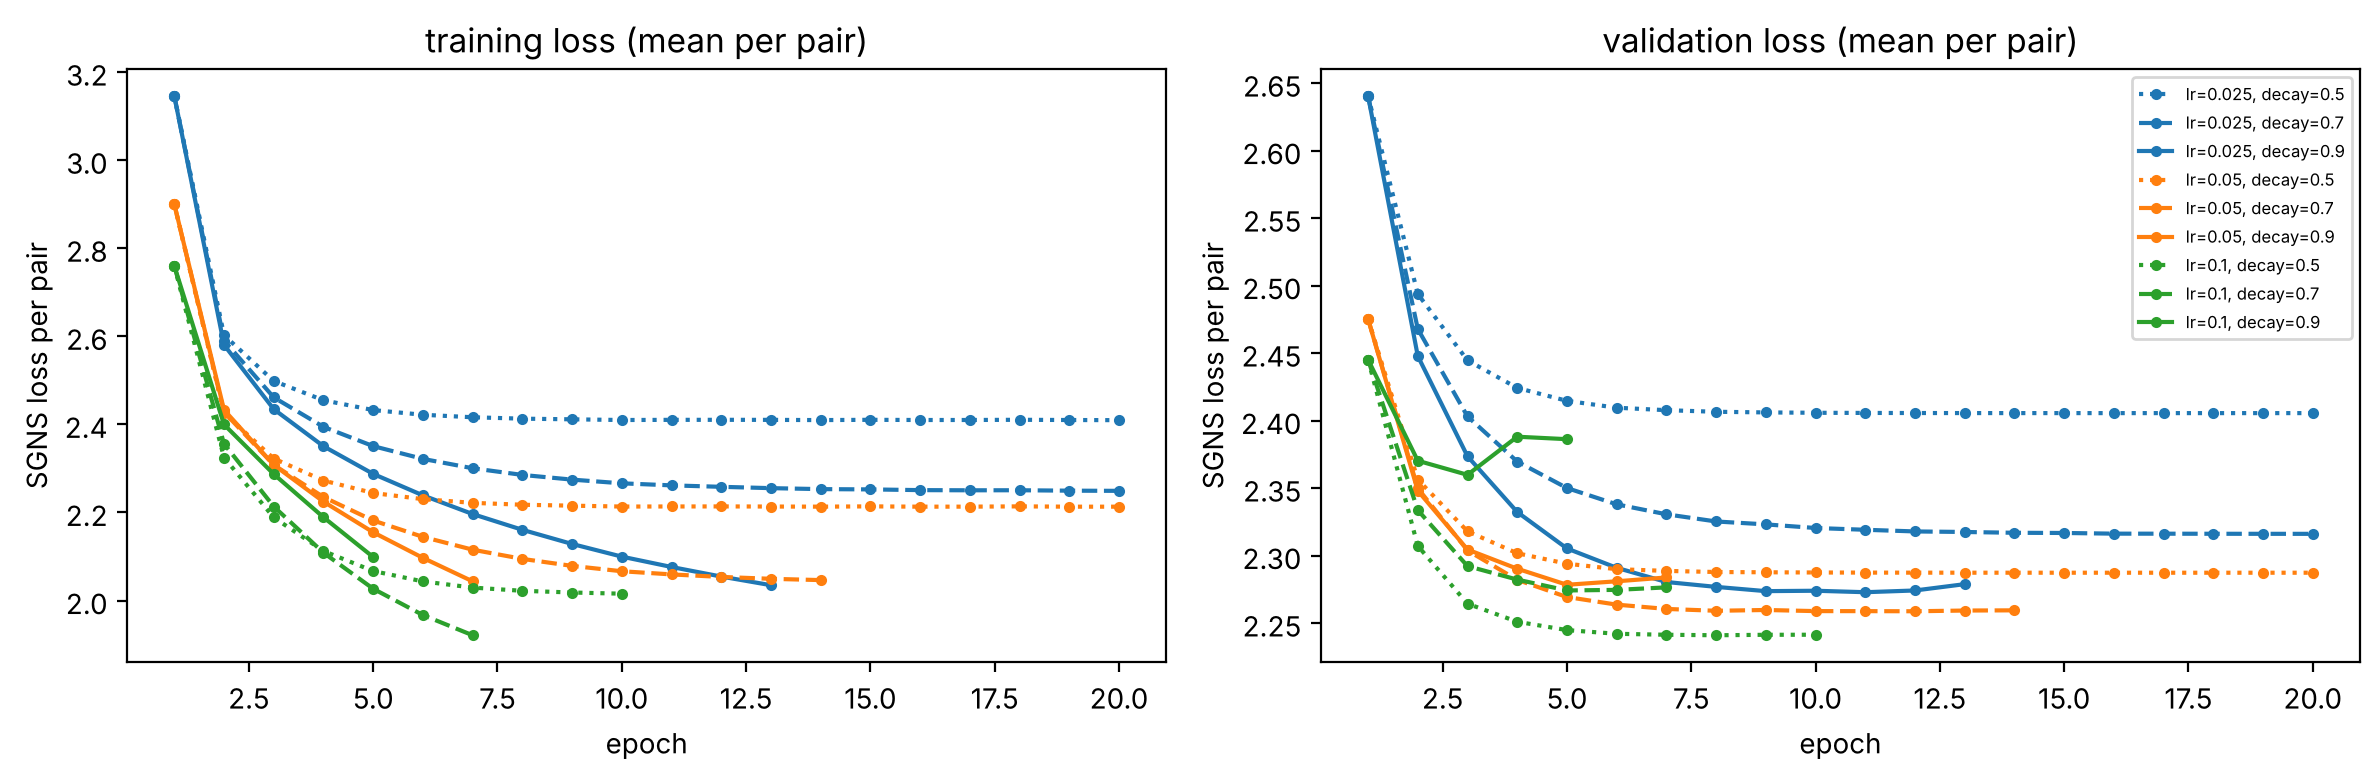

kept model after steps 1-3 (the window is validated in 3.2): window=2, dim=100, negatives=5, lr=0.1, decay=0.5, best epoch 8 (early stopping, patience 2), validation loss 2.2409
 epoch  train loss  val loss
     1      2.7602    2.4451
     2      2.3248    2.3071
     3      2.1888    2.2643
     4      2.1126    2.2509
     5      2.0671    2.2448
     6      2.0435    2.2420
     7      2.0295    2.2413
     8      2.0222    2.2409   <- kept
     9      2.0183    2.2413
    10      2.0156    2.2413


In [16]:
colors = {0.025: "tab:blue", 0.05: "tab:orange", 0.1: "tab:green"}
styles = {0.5: ":", 0.7: "--", 0.9: "-"}
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for lr in lr_grid:
    for d in decay_grid:
        h = hists[("grid", lr, d)]
        for a, k in zip(ax, ("train", "val")):
            a.plot(range(1, len(h[k]) + 1), h[k], color=colors[lr], linestyle=styles[d], marker=".", label=f"lr={lr}, decay={d}")
ax[0].set_title("training loss (mean per pair)"); ax[1].set_title("validation loss (mean per pair)")
for a in ax:
    a.set_xlabel("epoch"); a.set_ylabel("SGNS loss per pair")
ax[1].legend(fontsize=6, ncol=1, loc="upper right")
plt.tight_layout(); plt.show()

h = hists[chosen_key]
print(f"kept model after steps 1-3 (the window is validated in 3.2): window={W2V_WINDOW}, dim={best_dim}, negatives={best_neg}, lr={best_lr}, decay={best_decay}, "
      f"best epoch {chosen['epoch']} (early stopping, patience 2), validation loss {chosen['val']:.4f}")
print(f"{'epoch':>6}{'train loss':>12}{'val loss':>10}")
for e, (t_, v_) in enumerate(zip(h["train"], h["val"]), 1):
    print(f"{e:>6}{t_:>12.4f}{v_:>10.4f}" + ("   <- kept" if e == chosen["epoch"] else ""))

The embeddings used from now on are the input vectors $W_{in}$ of the kept model (one dense row per word). The output vectors $W_{out}$ are kept too, because section 3.1 needs them. The context window of this model is only provisional: section 3.2 validates the window (1 to 4) and, if another window wins, replaces this model by the one trained with that window.

### 1.5 Comparison of the three representations

Nearest neighbours (cosine similarity) of some query words. Self matches are removed.

In [17]:
queries = ["company", "said", "year", "he", "new", "million", "market", "price", "buy", "quickly"]
q_ids = [word2id[q] for q in queries]

def neighbors_known(q_ids):
    out = {}
    Q = np.stack([dense_row(pmi_rows[i], V) for i in q_ids])
    out["PMI"] = sparse_cosine(Q, pmi_rows, V)
    Q = np.stack([dense_row(tfidf_rows[i], n_docs) for i in q_ids])
    out["TF-IDF"] = sparse_cosine(Q, tfidf_rows, n_docs)
    unit = W_in / np.linalg.norm(W_in, axis=1, keepdims=True)
    out["Word2Vec"] = unit[q_ids] @ unit.T
    return out

def show_neighbours():
    sims = neighbors_known(q_ids)
    for n, (q, i) in enumerate(zip(queries, q_ids)):
        print(q)
        for name in ["PMI", "TF-IDF", "Word2Vec"]:
            s = sims[name][n].copy()
            s[i] = -np.inf
            print(f"   {name:9s}", [id2word[j] for j in np.argsort(-s)[:8]])

show_neighbours()

company
   PMI       ["'s", 'concern', 'digital', 'unwary', 'firm', 'continental', 'rundown', 'it']
   TF-IDF    ['the', '.', ',', 'said', 'a', "'s", 'in', 'earnings']
   Word2Vec  ['at&t', 'podium', 'airline', 'concern', 'ameritech', 'refiner', 'cboe', 'madison']
said
   PMI       [',', 'mr.', 'spokesman', "''", 'corp.', 'it', 'chairman', 'net']
   TF-IDF    ['.', ',', 'the', "''", '``', 'a', 'of', 'it']
   Word2Vec  ['noted', 'tan', 'asserted', 'says', 'roth', 'concedes', 'vista', 'commander']
year
   PMI       ['week', 'last', 'convenes', 'decade', 'fray', 'quarter', 'month', 'this']
   TF-IDF    ['earlier', '$', 'million', 'a', 'this', '<num>', 'last', 'share']
   Word2Vec  ['week', 'month', 'decade', 'february', 'fall', 'bailouts', 'worsen', 'rebound']
he
   PMI       ['that', 'mr.', 'it', 'his', 'she', 'has', 'they', 'sweaters']
   TF-IDF    ['his', '.', '``', "''", 'says', ',', 'to', 'the']
   Word2Vec  ['she', 'ms.', 'appreciated', 'zane', 'humans', 'groom', 'levine', 'defenses

In [18]:
def show_storage():
    # idealised = 4-byte values and 4-byte column indices; actual = bytes of the NumPy arrays really held in memory
    def actual(rows): return sum(c.nbytes + v.nbytes for c, v in rows) / 1e6
    d = W_in.shape[1]
    info = [
        ("PMI (PPMI), sparse rows", f"{V} x {V}", nnz_pmi, nnz_pmi / V ** 2, nnz_pmi * 8 / 1e6, actual(pmi_rows), V * V * 4 / 1e6),
        ("TF-IDF, sparse rows", f"{V} x {n_docs}", nnz_tfidf, nnz_tfidf / (V * n_docs), nnz_tfidf * 8 / 1e6, actual(tfidf_rows), V * n_docs * 4 / 1e6),
        ("Word2Vec W_in (extracted embeddings)", f"{V} x {d}", V * d, 1.0, V * d * 4 / 1e6, W_in.nbytes / 1e6, V * d * 4 / 1e6),
        ("Word2Vec W_in + W_out (all SGNS parameters)", f"2 x {V} x {d}", 2 * V * d, 1.0, 2 * V * d * 4 / 1e6, (W_in.nbytes + W_out.nbytes) / 1e6, 2 * V * d * 4 / 1e6),
    ]
    print(f"{'representation':46s}{'shape':>16s}{'non-zeros':>12s}{'density':>10s}{'idealised MB':>14s}{'NumPy MB':>10s}{'dense f32 MB':>14s}")
    for name, shape, nnz, dens, ideal, act, dense in info:
        print(f"{name:46s}{shape:>16s}{nnz:>12d}{dens:>10.2%}{ideal:>14.1f}{act:>10.1f}{dense:>14.1f}")
    print("idealised = 4-byte values (+ 4-byte column indices for the sparse rows); NumPy MB = bytes of the arrays actually held "
          f"(int64 indices, float32 sparse values, float{W_in.dtype.itemsize * 8} Word2Vec matrices); Python list/tuple/array-object overhead is not counted.")

show_storage()

representation                                           shape   non-zeros   density  idealised MB  NumPy MB  dense f32 MB
PMI (PPMI), sparse rows                          14622 x 14622      301215     0.14%           2.4       3.6         855.2
TF-IDF, sparse rows                               14622 x 8043      167554     0.14%           1.3       2.7         470.4
Word2Vec W_in (extracted embeddings)               14622 x 100     1462200   100.00%           5.8      11.7           5.8
Word2Vec W_in + W_out (all SGNS parameters)    2 x 14622 x 100     2924400   100.00%          11.7      23.4          11.7
idealised = 4-byte values (+ 4-byte column indices for the sparse rows); NumPy MB = bytes of the arrays actually held (int64 indices, float32 sparse values, float64 Word2Vec matrices); Python list/tuple/array-object overhead is not counted.


**Discussion of the comparison.** The first printout above uses the window-2 Word2Vec model of 1.4. Section 3.2 later selects window 3 and reprints the neighbours for that final model; both are discussed here. The inspection is qualitative and uses ten query words, so it indicates tendencies, not a ranking.

*Semantic quality.*
* **PMI** finds sensible neighbours for frequent words (`year` → week, decade, quarter, month; `buy` → sell, acquire, purchased; `he` → she, they, it; `new` → york, philadelphia, boston). It also returns rare words that share only a few contexts (`unwary`, `rundown` for `company`; `convenes`, `fray` for `year`; `tornado`, `ewdb` for `million`; `rowe`, `discrepencies` for `price`): PPMI gives large values to rare, specific contexts.
* **TF-IDF** neighbours of frequent words are dominated by other frequent tokens (`the`, `.`, `,` for `company`, `said`, `market`), because their rows overlap with many sentences. Where words are topical, the neighbours are words from the same *sentences* rather than similar words: `price` → order, filled, entered, buy-stop; `market` → stock, investors, strategist. That is co-occurrence in a document, not synonymy.
* **Word2Vec, window 2** gives useful neighbours for several frequent words (`said` → noted, asserted, says; `year` → week, month, decade; `market` → stock, prices, index, markets; `buy` → sell) but also odd ones (`company` → podium; `he` → appreciated, zane; `said` → tan, roth).
* **Word2Vec, final window 3** is not better by this inspection: `year`, `million` (billion) and `new` (york) stay good, but `he` → madd, mistake, subsequently; `said` → tan, noted, abc, bowes; `price` → reaches, underpin, tuitions. With about 191k training tokens many vectors are poorly estimated, and window 3 was selected over window 2 on a validation difference of about two unknown tokens (see 3.2), so we do not read this as evidence that one window is better.

None of the three is clearly best for semantic similarity. Word2Vec is the most compact and gives smooth similarities for frequent words, PMI is more precise but noisy for rare words, and TF-IDF captures topical co-occurrence.

*Sparsity, dimensionality, storage* (table above):

| | shape | non-zeros | idealised storage | NumPy arrays held |
|---|---|---|---|---|
| PMI (PPMI) | 14,622 x 14,622 | 301,215 (0.14%) | 2.4 MB | 3.6 MB |
| TF-IDF | 14,622 x 8,043 | 167,554 (0.14%) | 1.3 MB | 2.7 MB |
| Word2Vec `W_in` | 14,622 x 100 | dense | 5.8 MB | 11.7 MB (float64) |
| Word2Vec `W_in` + `W_out` | 2 x 14,622 x 100 | dense | 11.7 MB | 23.4 MB |

* The PMI and TF-IDF dimensions are tied to the data (vocabulary size, number of sentences), so they grow with the corpus. Word2Vec has a fixed, chosen dimension (100). Stored densely, PMI would need about 855 MB and TF-IDF about 470 MB as float32, so sparse storage is essential for them; they are sparse only because negative PMI is clipped and because most words occur in few sentences.
* Sparse coordinates are interpretable (each is a context word or a sentence) but very high-dimensional. Word2Vec coordinates are not interpretable but compact and similarity is a short dot product.
* For a fair comparison, Word2Vec needs both matrices during training and for the Part 3 query (the query uses `W_out`), i.e. 11.7 MB idealised, not 5.8 MB. The idealised numbers assume 4-byte values and indices; the "NumPy arrays held" column is what this notebook really stores (int64 indices, float64 embeddings) and excludes Python list/object overhead.

## Part 2: Hidden Markov Model and Viterbi

### 2.1 Estimating the HMM

States are POS tags, observations are (preprocessed) words. From the tagged training sentences we count

* initial counts: how often each tag starts a sentence,
* transition counts: how often tag $s$ is followed by tag $t$,
* emission counts: how often tag $t$ emits word $x$,

and turn them into probabilities with **add-$\alpha$ smoothing**:

$$\pi_t=\frac{\#(\text{start}=t)+\alpha_\pi}{N+\alpha_\pi T},\quad
a_{st}=\frac{\#(s\to t)+\alpha_a}{\#(s\to\cdot)+\alpha_a T},\quad
b_t(x)=\frac{\#(t,x)+\alpha_b}{\#(t)+\alpha_b\,(V+1)}$$

with $T$ the number of tags. We use $\alpha_\pi=\alpha_a$ and tune $\alpha_a$ and $\alpha_b$.

**Unknown words.** Emission has $V+1$ columns, the last one is for `<UNK>`. A word that never appeared in training has no emission of its own, so it uses the `<UNK>` column. Its counts are taken from the *rare* training words: all training words that appear at most `unk_max` times are counted as examples of unknown words, $\#(t,\texttt{UNK})=\sum_{\text{rare }x}\#(t,x)$. This estimates which tags unseen words usually have (mostly nouns, adjectives, ...). The rare words also keep their own regular columns.
`unk_max` is tuned too.

### 2.2 Viterbi decoding

Viterbi is done on log probabilities (sums instead of products), so long sentences cannot underflow. `delta[t]` is the best log-score of any path ending in tag `t`, and back-pointers recover the best tag sequence.

**Emission normalisation.** Rare-word counts are pooled into the `<UNK>` column while the same words also keep their own columns, so the emission counts of tag $t$ add up to $\#(t)+\#_{rare}(t)$. The denominator is computed over **all** $V+1$ columns (`emit.sum(1)`), so every row of $b_t(\cdot)$ sums to exactly 1 (checked below). A first version divided by the sum over the $V$ word columns only; its rows summed to more than 1, by an amount that differs from tag to tag (the largest row sum was 1.41, so it was *not* a uniform factor). Section 2.1 below reports the validation effect of the two versions.

`unk_max` also acts as the vocabulary control of the HMM: every training word that appears at most `unk_max` times contributes to the unknown-word emission.

In [19]:
def hmm_counts(ids_list, tags_list):
    init = np.zeros(n_tags)
    trans = np.zeros((n_tags, n_tags))
    emit = np.zeros((n_tags, V + 1))
    for ids, tags in zip(ids_list, tags_list):
        init[tags[0]] += 1
        np.add.at(trans, (tags[:-1], tags[1:]), 1)
        np.add.at(emit, (tags, ids), 1)
    return init, trans, emit

def fit_hmm(counts, a_trans, a_emit, unk_max, renorm=True):
    init, trans, emit = counts
    emit = emit.copy()
    freq = emit.sum(0)
    rare = (freq > 0) & (freq <= unk_max)
    emit[:, UNK] = emit[:, rare].sum(1)
    log_pi = np.log((init + a_trans) / (init.sum() + a_trans * n_tags))
    log_A = np.log((trans + a_trans) / (trans.sum(1, keepdims=True) + a_trans * n_tags))
    # renorm=True: the denominator covers all V+1 columns (incl. <UNK>), so every row of b sums to 1.
    # renorm=False is the earlier version (denominator over the V word columns only), kept only for the comparison below.
    tag_total = emit.sum(1, keepdims=True) if renorm else emit[:, :V].sum(1, keepdims=True)
    log_B = np.log((emit + a_emit) / (tag_total + a_emit * (V + 1)))
    return log_pi, log_A, log_B

def viterbi(log_pi, log_A, log_emit):
    # log_emit: (sentence length, n_tags)
    n = log_emit.shape[0]
    delta = log_pi + log_emit[0]
    back = np.zeros((n, n_tags), dtype=int)
    for i in range(1, n):
        scores = delta[:, None] + log_A
        back[i] = scores.argmax(axis=0)
        delta = scores.max(axis=0) + log_emit[i]
    path = [int(delta.argmax())]
    for i in range(n - 1, 0, -1):
        path.append(int(back[i][path[-1]]))
    return np.array(path[::-1])

def decode(ids_list, model, oov_pos=None, oov_log_emit=None):
    # oov_pos / oov_log_emit let Part 3 replace the emission scores of chosen unknown tokens
    log_pi, log_A, log_B = model
    where = {p: n for n, p in enumerate(oov_pos)} if oov_pos is not None else {}
    preds = []
    for s, ids in enumerate(ids_list):
        log_emit = log_B[:, ids].T.copy()
        if where:
            for i in np.flatnonzero(ids == UNK):
                log_emit[i] = oov_log_emit[where[(s, i)]]
        preds.append(viterbi(log_pi, log_A, log_emit))
    return preds

def token_accuracy(preds, tags_list, ids_list):
    p, g = np.concatenate(preds), np.concatenate(tags_list)
    unk = np.concatenate(ids_list) == UNK
    return (p == g).mean(), (p[unk] == g[unk]).mean()

**Tuning the smoothing and the unknown-word threshold** on the validation set (token accuracy). The test set is not used.

In [20]:
counts = hmm_counts(train_ids, train_tags)

a_t_grid, a_e_grid, unk_grid = [0.001, 0.01, 0.1, 1.0, 3.0, 10.0], [0.0001, 0.001, 0.01, 0.1], [1, 2, 3, 4, 5]
grid = []
for a_t in a_t_grid:
    for a_e in a_e_grid:
        for unk_max in unk_grid:
            model = fit_hmm(counts, a_t, a_e, unk_max)
            acc_all, acc_unk = token_accuracy(decode(val_ids, model), val_tags, val_ids)
            grid.append((acc_all, acc_unk, a_t, a_e, unk_max))

grid.sort(reverse=True)
print("top 8 settings on validation   (accuracy, unknown-word accuracy, alpha_a, alpha_b, unk_max)")
for g in grid[:8]:
    print(f"   {g[0]:.4f}  {g[1]:.4f}   {g[2]}  {g[3]}  {g[4]}")
print("worst setting:", f"{grid[-1][0]:.4f}", grid[-1][2:])

_, _, ALPHA_TRANS, ALPHA_EMIT, UNK_MAX = grid[0]
print("\nchosen:", dict(alpha_trans=ALPHA_TRANS, alpha_emit=ALPHA_EMIT, unk_max=UNK_MAX))
for name_, val_, opts_ in [("alpha_trans", ALPHA_TRANS, a_t_grid), ("alpha_emit", ALPHA_EMIT, a_e_grid), ("unk_max", UNK_MAX, unk_grid)]:
    print(f"   {name_}={val_}: {'at the edge of the grid' if val_ in (min(opts_), max(opts_)) else 'interior of the grid'}")
n_close = sum(g[0] >= grid[0][0] - 0.0005 for g in grid)
print(f"{n_close} of {len(grid)} settings are within 0.0005 accuracy of the best one (the top settings are essentially tied)")

top 8 settings on validation   (accuracy, unknown-word accuracy, alpha_a, alpha_b, unk_max)
   0.9477  0.5444   0.01  0.001  5
   0.9477  0.5444   0.01  0.0001  5
   0.9477  0.5429   0.01  0.001  4
   0.9477  0.5429   0.01  0.0001  4
   0.9476  0.5444   0.001  0.0001  5
   0.9476  0.5429   0.001  0.0001  4
   0.9475  0.5444   0.1  0.001  5
   0.9475  0.5444   0.001  0.001  5
worst setting: 0.9381 (0.001, 0.1, 5)

chosen: {'alpha_trans': 0.01, 'alpha_emit': 0.001, 'unk_max': 5}
   alpha_trans=0.01: interior of the grid
   alpha_emit=0.001: interior of the grid
   unk_max=5: at the edge of the grid
24 of 120 settings are within 0.0005 accuracy of the best one (the top settings are essentially tied)


**Check of the emission normalisation (validation only).** Every row of $b_t(\cdot)$ should sum to 1. The table compares the two denominators with the chosen smoothing settings.

In [21]:
for flag in (False, True):
    m_ = fit_hmm(counts, ALPHA_TRANS, ALPHA_EMIT, UNK_MAX, renorm=flag)
    sums = np.exp(m_[2]).sum(1)
    a_, u_ = token_accuracy(decode(val_ids, m_), val_tags, val_ids)
    print(f"renorm={str(flag):5s}  emission row sums: min {sums.min():.4f}, max {sums.max():.4f}   |   validation accuracy {a_:.4f}, unknown-word accuracy {u_:.4f}")
assert np.allclose(np.exp(fit_hmm(counts, ALPHA_TRANS, ALPHA_EMIT, UNK_MAX)[2]).sum(1), 1.0)
print("the final model (renorm=True) has exactly normalised emission rows")

renorm=False  emission row sums: min 1.0000, max 1.4148   |   validation accuracy 0.9472, unknown-word accuracy 0.5444


renorm=True   emission row sums: min 1.0000, max 1.0000   |   validation accuracy 0.9477, unknown-word accuracy 0.5444
the final model (renorm=True) has exactly normalised emission rows


**Lowercasing ablation (validation only).** Section 1.1 chose to lowercase the text. Here that choice is measured instead of assumed: the same HMM with the tuned smoothing settings, trained on the train split and scored on the validation split, with and without lowercasing (numbers are still mapped to `<num>`). The smoothing settings were tuned on the lowercased text, so the cased variant is, if anything, slightly disadvantaged.

In [22]:
def norm_cased(t):
    return "<num>" if any(ch.isdigit() for ch in t) else t
cased_train = [[norm_cased(t) for t in s] for s in train_tokens]
cased_val = [[norm_cased(t) for t in s] for s in val_tokens]
nnp = tag_names.index("NNP")
print(f"{'text':18s}{'vocabulary':>12s}{'val acc':>10s}{'unk acc':>10s}{'NNP F1':>9s}")
ablation = {}
for name_, trw, vlw in [("lowercased (used)", train_words, val_words), ("cased", cased_train, cased_val)]:
    r_ = hmm_eval_generic(trw, vlw, 1, ALPHA_TRANS, ALPHA_EMIT, UNK_MAX)
    ablation[name_] = dict(V=r_["V"], acc=r_["acc"], unk=r_["unk_acc"], nnp=f1_of_tag(r_["gold"], r_["pred"], nnp))
    print(f"{name_:18s}{r_['V']:>12d}{r_['acc']:>10.4f}{r_['unk_acc']:>10.4f}{ablation[name_]['nnp']:>9.4f}")

text                vocabulary   val acc   unk acc   NNP F1


lowercased (used)        14622    0.9477    0.5444   0.8889


cased                    16383    0.9604    0.5525   0.9548


**Reading the ablation.** Keeping the case gives a *larger* vocabulary (16,383 instead of 14,622 types, because `The` and `the` are separate entries) and a clearly better tagger on validation: accuracy 0.9604 vs 0.9477, unknown-word accuracy 0.5525 vs 0.5444 and `NNP` F1 0.9548 vs 0.8889. So lowercasing costs about 1.3 points of validation accuracy, almost all of it on proper nouns, and the earlier statement that lowercasing was nearly free was wrong. We keep lowercasing for the whole notebook because all three representations (PMI, TF-IDF, Word2Vec) and all four HMMs must see the same text, and because pooling `The`/`the` helps the embeddings on a corpus this small. The price is the accuracy loss measured here; a cased HMM (or a lowercased word plus a capitalisation feature) is the obvious improvement and is listed in the limitations.

### 2.3 Evaluation of the baseline HMM (test set)

Metrics: token accuracy, and precision / recall / F1 computed per tag from the confusion counts and then averaged. *Macro* averages the tags equally (rare tags matter as much as frequent ones), *weighted* averages them by their number of gold tokens. For accuracy, micro precision = recall = F1, so it is reported once.
The same numbers are given for the **unknown words** alone, i.e. test tokens that are not in the training vocabulary.

In [23]:
def tag_report(gold, pred):
    conf = np.zeros((n_tags, n_tags))
    np.add.at(conf, (gold, pred), 1)
    tp = np.diag(conf)
    support = conf.sum(1)
    predicted = conf.sum(0)
    prec = np.divide(tp, predicted, out=np.zeros(n_tags), where=predicted > 0)
    rec = np.divide(tp, support, out=np.zeros(n_tags), where=support > 0)
    f1 = np.divide(2 * prec * rec, prec + rec, out=np.zeros(n_tags), where=(prec + rec) > 0)
    seen = support > 0
    wts = support / support.sum()
    return {"acc": tp.sum() / support.sum(),
            "P macro": prec[seen].mean(), "R macro": rec[seen].mean(), "F1 macro": f1[seen].mean(),
            "P wtd": (prec * wts).sum(), "R wtd": (rec * wts).sum(), "F1 wtd": (f1 * wts).sum()}

def evaluate(preds, tags_list, ids_list):
    p, g = np.concatenate(preds), np.concatenate(tags_list)
    unk = np.concatenate(ids_list) == UNK
    return tag_report(g, p), tag_report(g[unk], p[unk])

def print_reports(results):
    # results: {system name: (report on all tokens, report on unknown tokens)}
    keys = ["acc", "P macro", "R macro", "F1 macro", "P wtd", "R wtd", "F1 wtd"]
    for title, which in [("all test tokens", 0), ("unknown test tokens only", 1)]:
        print(title)
        print(f"   {'system':22s}" + "".join(f"{k:>10s}" for k in keys))
        for name, res in results.items():
            print(f"   {name:22s}" + "".join(f"{res[which][k]:>10.4f}" for k in keys))
        print()

In [24]:
baseline = fit_hmm(counts, ALPHA_TRANS, ALPHA_EMIT, UNK_MAX)
base_preds_test = decode(test_ids, baseline)
base_report = evaluate(base_preds_test, test_tags, test_ids)

n_unk_test = int(np.sum(np.concatenate(test_ids) == UNK))
print("test tokens:", sum(len(s) for s in test_ids), "| unknown test tokens:", n_unk_test, "\n")
print_reports({"baseline HMM": base_report})

test tokens: 47377 | unknown test tokens: 2766 

all test tokens
   system                       acc   P macro   R macro  F1 macro     P wtd     R wtd    F1 wtd
   baseline HMM              0.9371    0.9373    0.9076    0.9152    0.9377    0.9371    0.9371

unknown test tokens only
   system                       acc   P macro   R macro  F1 macro     P wtd     R wtd    F1 wtd
   baseline HMM              0.5528    0.2493    0.2323    0.2302    0.5335    0.5528    0.5320



The baseline reaches about 94% token accuracy overall, but on unknown words it only gets about 55%: the `<UNK>` emission only knows the *tag* statistics of rare words and nothing about the word itself or its neighbours. Part 3 tries to improve this.

## Part 3: Embedding-assisted HMM

### 3.1 Strategy

An unknown word was never seen in training, so it has no row or vector in any representation. What the three representations do have are vectors for the *known* words around it. The idea is to build a vector for the unknown word from its **context** in the sentence, find the known words that are most similar to it, and let those words vote for the tag:

1. **Query vector of the unknown token.**
   * *PMI*: it is treated as a word that was seen once with each context word $c$ in its $\pm w$ window, so its PPMI vector is $\max(0,\log\frac{n_c}{m\,P_\alpha(c)})$ ($n_c$ = number of times $c$ is in the window, $m$ = window size in words).
   * *TF-IDF*: its document vector is the sum of the TF-IDF rows of the known words in its own sentence (sentence = document).
   * *Word2Vec*: the average of the output vectors $u_c$ of the known words in the $\pm w$ window. This is the direction the skip-gram model would use to predict a word from its context, and it is compared with the input vectors $v$ of all known words.
2. **Neighbours.** The $k$ known words with the highest cosine similarity to the query vector.
3. **Tag distribution of the neighbours.** $q(t)=\sum_{j\le k}\omega_j\,P(t\mid x_j)$, with $P(t\mid x_j)$ taken from the training counts and weights $\omega_j\propto\exp(\cos_j/\tau)$ (temperature $\tau$). It is smoothed: $q\leftarrow(1-\varepsilon)q+\varepsilon P(t)$.
4. **Emission score.** The baseline `<UNK>` emission is multiplied by the likelihood ratio $q(t)/P(t)$, raised to a power $\beta$ that controls how much the neighbours are trusted:

$$\log b_t(\text{unk}) = \log b_t(\texttt{UNK}) + \beta\,\bigl(\log q(t)-\log P(t)\bigr)$$

With $\beta=0$ the system is exactly the baseline. Only unknown tokens are changed; known words, transitions and Viterbi are untouched. If an unknown token has no known word around it, the baseline emission is used.

The hyperparameters of this step are $k$, $\tau$, $\beta$, $\varepsilon$, plus the window and $\alpha$ of the representation itself.

In [25]:
C_known = counts[2][:, :V]                                    # tag x word counts
tag_prior = (C_known.sum(1) + 1) / (C_known.sum() + n_tags)   # P(t)
tag_given_word = (C_known / C_known.sum(0, keepdims=True)).T  # V x n_tags, P(t | word)

def oov_positions(ids_list):
    return [(s, i) for s, ids in enumerate(ids_list) for i in np.flatnonzero(ids == UNK)]

def window_context(ids, i, window):
    lo, hi = max(0, i - window), min(len(ids), i + window + 1)
    return [x for j, x in zip(range(lo, hi), ids[lo:hi]) if x != UNK and j != i]

K_MAX = 200   # fixed cap on stored neighbours per unknown token; must be >= the largest k searched   # neighbours kept per unknown token

def pmi_neighbors(ids_list, pos, rows, ctx_prob, window, batch=500):
    idx, sims, ok = [], [], np.zeros(len(pos), bool)
    for b in range(0, len(pos), batch):
        part = pos[b:b + batch]
        Q = np.zeros((len(part), V), dtype=np.float32)
        for n, (s, i) in enumerate(part):
            ctx = window_context(ids_list[s], i, window)
            if ctx:
                c, cnt = np.unique(ctx, return_counts=True)
                Q[n, c] = np.maximum(0, np.log(cnt / (cnt.sum() * ctx_prob[c])))
                ok[b + n] = True
        a, v = top_k(sparse_cosine(Q, rows, V), K_MAX)
        idx.append(a); sims.append(v)
    return np.vstack(idx), np.vstack(sims), ok

def tfidf_neighbors(ids_list, pos, rows, dim, batch=500):
    idx, sims, ok = [], [], np.zeros(len(pos), bool)
    for b in range(0, len(pos), batch):
        part = pos[b:b + batch]
        Q = np.zeros((len(part), dim), dtype=np.float32)
        for n, (s, i) in enumerate(part):
            ctx = [x for x in ids_list[s] if x != UNK]
            for x in ctx:
                Q[n, rows[x][0]] += rows[x][1]
            ok[b + n] = len(ctx) > 0
        a, v = top_k(sparse_cosine(Q, rows, dim), K_MAX)
        idx.append(a); sims.append(v)
    return np.vstack(idx), np.vstack(sims), ok

def w2v_neighbors(ids_list, pos, w_in, w_out, window):
    Q = np.zeros((len(pos), w_out.shape[1]))
    ok = np.zeros(len(pos), bool)
    for n, (s, i) in enumerate(pos):
        ctx = window_context(ids_list[s], i, window)
        if ctx:
            Q[n] = w_out[ctx].mean(0)
            ok[n] = True
    Q /= np.maximum(np.linalg.norm(Q, axis=1, keepdims=True), 1e-9)
    unit = w_in / np.linalg.norm(w_in, axis=1, keepdims=True)
    idx, sims = top_k(Q @ unit.T, K_MAX)
    return idx, sims, ok

In [26]:
def oov_log_emission(nb, model, k, tau, beta, eps):
    idx, sims, ok = nb
    base = model[2][:, UNK]
    w = np.exp((sims[:, :k] - sims[:, :1]) / tau)
    w /= w.sum(1, keepdims=True)
    q = np.einsum("nk,nkt->nt", w, tag_given_word[idx[:, :k]])
    q = (1 - eps) * q + eps * tag_prior
    out = base[None, :] + beta * (np.log(q) - np.log(tag_prior)[None, :])
    return np.where(ok[:, None], out, base[None, :])

def search_integration(nb, pos, model, ks, taus, betas, epss):
    # returns list of (val accuracy, val unknown accuracy, k, tau, beta, eps), best first
    res = []
    for k in ks:
        for tau in taus:
            for beta in betas:
                for eps in epss:
                    le = oov_log_emission(nb, model, k, tau, beta, eps)
                    a, u = token_accuracy(decode(val_ids, model, pos, le), val_tags, val_ids)
                    res.append((a, u, k, tau, beta, eps))
    res.sort(reverse=True)
    return res

val_pos = oov_positions(val_ids)
print("unknown tokens in validation:", len(val_pos))
base_val = token_accuracy(decode(val_ids, baseline), val_tags, val_ids)
print(f"baseline on validation: accuracy {base_val[0]:.4f}, unknown-word accuracy {base_val[1]:.4f}")

unknown tokens in validation: 687
baseline on validation: accuracy 0.9477, unknown-word accuracy 0.5444


### 3.2 Hyperparameter tuning (validation set only)

**Step 1: the representation itself.** For PMI we try several windows and two values of the context smoothing $\alpha$; for Word2Vec four windows (1, 2, 3, 4; the other Word2Vec settings were already tuned in 1.4, and each new window retrains the model with those settings). TF-IDF has no hyperparameters of its own. Each candidate is scored by the best validation accuracy of the assisted HMM over a small grid of $(k,\tau,\beta,\varepsilon)$. **The selected configuration is then applied**: if it differs from the starting configuration, the PMI rows are rebuilt / the selected Word2Vec model replaces the current one, and assertions check that the final representations really use the selected values.

In [27]:
small_grid = dict(ks=[25, 100], taus=[0.3, 1.0], betas=[0.5, 1.0], epss=[0.2])

pmi_candidates = {}
for window in [1, 2, 3, 5]:
    for alpha in [0.75, 1.0]:
        t0 = time.time()
        w_, c_, n_ = cooccurrence(train_ids, window)
        rows_, prob_ = ppmi_rows(w_, c_, n_, alpha)
        nb = pmi_neighbors(val_ids, val_pos, rows_, prob_, window)
        best = search_integration(nb, val_pos, baseline, **small_grid)[0]
        pmi_candidates[(window, alpha)] = best
        print(f"PMI window={window} alpha={alpha:<4}  val acc {best[0]:.4f}  unknown acc {best[1]:.4f}  ({time.time() - t0:.0f}s)")

# select on validation and APPLY the selection
best_pmi_cfg = max(pmi_candidates, key=lambda c: pmi_candidates[c][:2])
print("\nselected PMI (window, alpha):", best_pmi_cfg, "| starting configuration:", PMI_BUILT)
pmi_changed = best_pmi_cfg != PMI_BUILT
if pmi_changed:
    PMI_WINDOW, PMI_ALPHA = best_pmi_cfg
    co_w, co_c, co_n = cooccurrence(train_ids, PMI_WINDOW)
    pmi_rows, pmi_ctx_prob = ppmi_rows(co_w, co_c, co_n, PMI_ALPHA)
    PMI_BUILT = (PMI_WINDOW, PMI_ALPHA)
    nnz_pmi = sum(len(r[0]) for r in pmi_rows)
    print("the selection differs from the starting configuration -> PMI rows rebuilt with the selected values")
assert best_pmi_cfg == (PMI_WINDOW, PMI_ALPHA) == PMI_BUILT
print("assertion passed: the PMI representation used from now on was built with the selected window and alpha")

PMI window=1 alpha=0.75  val acc 0.9486  unknown acc 0.5706  (4s)


PMI window=1 alpha=1.0   val acc 0.9488  unknown acc 0.5735  (4s)


PMI window=2 alpha=0.75  val acc 0.9497  unknown acc 0.5983  (4s)


PMI window=2 alpha=1.0   val acc 0.9493  unknown acc 0.5837  (4s)


PMI window=3 alpha=0.75  val acc 0.9493  unknown acc 0.5910  (4s)


PMI window=3 alpha=1.0   val acc 0.9493  unknown acc 0.5895  (5s)


PMI window=5 alpha=0.75  val acc 0.9483  unknown acc 0.5619  (5s)


PMI window=5 alpha=1.0   val acc 0.9484  unknown acc 0.5619  (5s)

selected PMI (window, alpha): (2, 0.75) | starting configuration: (2, 0.75)
assertion passed: the PMI representation used from now on was built with the selected window and alpha


In [28]:
w2v_candidates = {}
for window in [1, 2, 3, 4]:
    t0 = time.time()
    if window == W2V_WINDOW:
        wi, wo, ep, vl_ = W_in, W_out, chosen["epoch"], chosen["val"]
    else:
        m_, _ = train_w2v(window, best_dim, best_neg, best_lr, decay=best_decay)
        wi, wo, ep, vl_ = m_["W_in"], m_["W_out"], m_["epoch"], m_["val"]
    nb = w2v_neighbors(val_ids, val_pos, wi, wo, window)
    best = search_integration(nb, val_pos, baseline, **small_grid)[0]
    w2v_candidates[window] = dict(best=best, W_in=wi, W_out=wo, epoch=ep, val=vl_)
    print(f"Word2Vec window={window}  best epoch {ep:2d}  val acc {best[0]:.4f}  unknown acc {best[1]:.4f}  ({time.time() - t0:.0f}s)")

# select on validation and APPLY the selection
best_w2v_window = max(w2v_candidates, key=lambda c: w2v_candidates[c]["best"][:2])
print("\nselected Word2Vec window:", best_w2v_window, "| starting window:", W2V_WINDOW)
w2v_changed = best_w2v_window != W2V_WINDOW
if w2v_changed:
    W2V_WINDOW = best_w2v_window
    W_in, W_out = w2v_candidates[W2V_WINDOW]["W_in"], w2v_candidates[W2V_WINDOW]["W_out"]
    w2v_final.update(window=W2V_WINDOW, epoch=w2v_candidates[W2V_WINDOW]["epoch"], val=w2v_candidates[W2V_WINDOW]["val"])
    print("the selection differs from the starting window -> the Word2Vec model of the selected window is now the final model")
assert best_w2v_window == W2V_WINDOW == w2v_final["window"]
assert W_in is w2v_candidates[W2V_WINDOW]["W_in"] and W_out is w2v_candidates[W2V_WINDOW]["W_out"]
print("assertion passed: the Word2Vec embeddings used from now on were trained with the selected window")
for w_, d_ in w2v_candidates.items():       # free the weights of the windows that were not kept
    if w_ != W2V_WINDOW:
        d_["W_in"] = d_["W_out"] = None

if pmi_changed or w2v_changed:
    print("\nSelection changed a Part 1 representation -> Section 1.5 is recomputed for the FINAL representations:\n")
    show_neighbours(); print(); show_storage()
else:
    print("\nThe selected configurations equal the ones used in Part 1, so the Section 1.5 outputs already describe the final representations.")

Word2Vec window=1  best epoch 10  val acc 0.9486  unknown acc 0.5735  (41s)


Word2Vec window=2  best epoch  8  val acc 0.9487  unknown acc 0.5735  (2s)


Word2Vec window=3  best epoch  6  val acc 0.9488  unknown acc 0.5764  (75s)


Word2Vec window=4  best epoch  6  val acc 0.9486  unknown acc 0.5706  (97s)

selected Word2Vec window: 3 | starting window: 2
the selection differs from the starting window -> the Word2Vec model of the selected window is now the final model
assertion passed: the Word2Vec embeddings used from now on were trained with the selected window

Selection changed a Part 1 representation -> Section 1.5 is recomputed for the FINAL representations:



company
   PMI       ["'s", 'concern', 'digital', 'unwary', 'firm', 'continental', 'rundown', 'it']
   TF-IDF    ['the', '.', ',', 'said', 'a', "'s", 'in', 'earnings']
   Word2Vec  ['railroad', 'loral', 'consumer-electronics', 'trinova', 'fda', 'adversely', 'post', 'coating']
said
   PMI       [',', 'mr.', 'spokesman', "''", 'corp.', 'it', 'chairman', 'net']
   TF-IDF    ['.', ',', 'the', "''", '``', 'a', 'of', 'it']
   Word2Vec  ['tan', 'noted', 'abc', 'bowes', 'coatings', 'basir', 'bristol-myers', 'marlin']
year
   PMI       ['week', 'last', 'convenes', 'decade', 'fray', 'quarter', 'month', 'this']
   TF-IDF    ['earlier', '$', 'million', 'a', 'this', '<num>', 'last', 'share']
   Word2Vec  ['week', 'frenzied', 'month', 'decade', 'restatement', 'trailed', 'non-auto', 'hectic']
he
   PMI       ['that', 'mr.', 'it', 'his', 'she', 'has', 'they', 'sweaters']
   TF-IDF    ['his', '.', '``', "''", 'says', ',', 'to', 'the']
   Word2Vec  ['madd', 'mistake', 'subsequently', 'affidavit', 'elabo

**Step 2: the integration parameters.** With the representations fixed, a finer grid over $k$, $\tau$, $\beta$ and $\varepsilon$ is searched for each of the three systems. The criterion is again validation token accuracy (unknown-word accuracy is shown next to it).

In [29]:
full_grid = dict(ks=[10, 25, 50, 100, 150, 200], taus=[0.1, 0.3, 1.0, 3.0, 5.0, 10.0],
                 betas=[0.1, 0.25, 0.5, 1.0, 1.5, 2.0], epss=[0.01, 0.05, 0.2, 0.5, 0.8])
assert max(full_grid["ks"]) <= K_MAX

val_nb = {
    "PMI-assisted": pmi_neighbors(val_ids, val_pos, pmi_rows, pmi_ctx_prob, PMI_WINDOW),
    "TF-IDF-assisted": tfidf_neighbors(val_ids, val_pos, tfidf_rows, n_docs),
    "Word2Vec-assisted": w2v_neighbors(val_ids, val_pos, W_in, W_out, W2V_WINDOW),
}

tuned = {}
for name, nb in val_nb.items():
    t0 = time.time()
    res = search_integration(nb, val_pos, baseline, **full_grid)
    tuned[name] = res[0]
    a, u, k, tau, beta, eps = res[0]
    print(f"{name:18s} val acc {a:.4f}  unknown acc {u:.4f}   k={k} tau={tau} beta={beta} eps={eps}   ({time.time() - t0:.0f}s)")
print(f"{'baseline':18s} val acc {base_val[0]:.4f}  unknown acc {base_val[1]:.4f}")

print("\nselected values that sit on the edge of the searched grid:")
for name, (a, u, k, tau, beta, eps) in tuned.items():
    edge = [n_ for n_, v_, o_ in [("k", k, full_grid["ks"]), ("tau", tau, full_grid["taus"]), ("beta", beta, full_grid["betas"]), ("eps", eps, full_grid["epss"])]
            if v_ in (min(o_), max(o_))]
    print(f"   {name:18s}", ", ".join(edge) if edge else "none")

PMI-assisted       val acc 0.9497  unknown acc 0.5983   k=100 tau=1.0 beta=1.0 eps=0.2   (209s)


TF-IDF-assisted    val acc 0.9479  unknown acc 0.5517   k=25 tau=10.0 beta=0.25 eps=0.5   (206s)


Word2Vec-assisted  val acc 0.9496  unknown acc 0.6012   k=50 tau=0.3 beta=1.5 eps=0.5   (205s)
baseline           val acc 0.9477  unknown acc 0.5444

selected values that sit on the edge of the searched grid:
   PMI-assisted       none
   TF-IDF-assisted    tau
   Word2Vec-assisted  none


Sensitivity of each system to $\beta$ (the other parameters fixed at their best values), to show how the amount of trust in the neighbours changes the validation result.

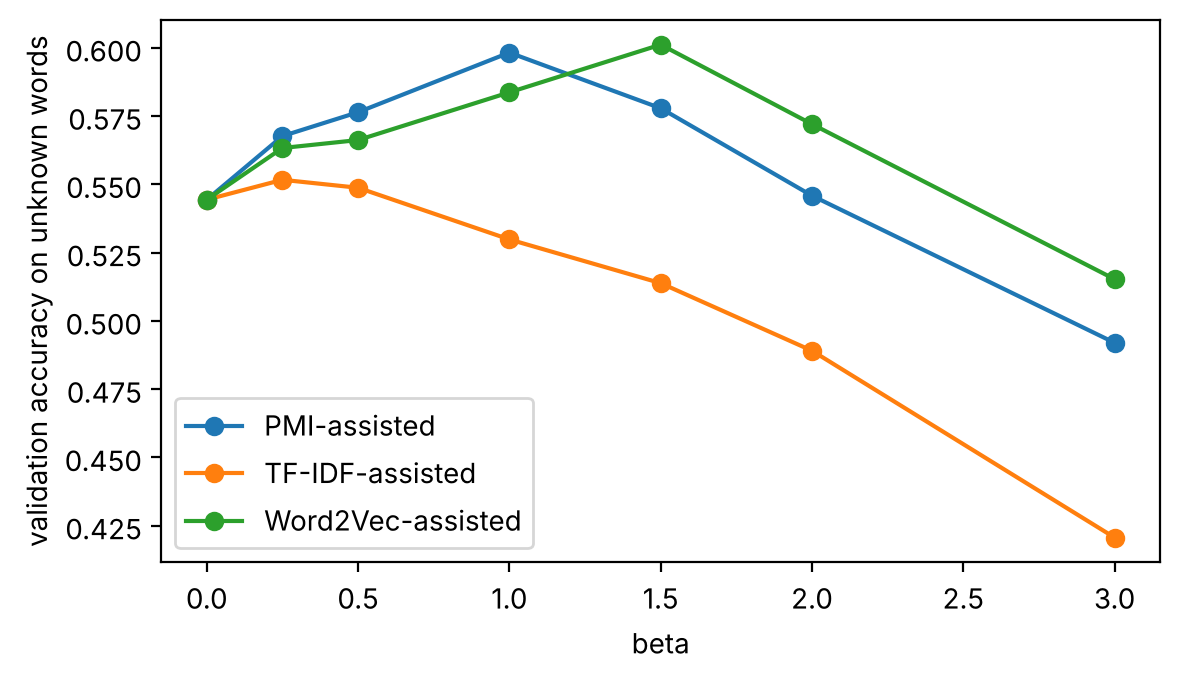

In [30]:
betas = [0.0, 0.25, 0.5, 1.0, 1.5, 2.0, 3.0]
plt.figure(figsize=(6, 3.5))
for name, nb in val_nb.items():
    _, _, k, tau, _, eps = tuned[name]
    accs = []
    for b in betas:
        le = oov_log_emission(nb, baseline, k, tau, b, eps)
        accs.append(token_accuracy(decode(val_ids, baseline, val_pos, le), val_tags, val_ids)[1])
    plt.plot(betas, accs, marker="o", label=name)
plt.xlabel("beta"); plt.ylabel("validation accuracy on unknown words")
plt.legend(); plt.tight_layout(); plt.show()

### 3.3 Final comparison on the test set

All four systems use the HMM trained on the training split only. The values chosen above are used, nothing is changed after seeing test results.

In [31]:
test_pos = oov_positions(test_ids)
test_nb = {
    "PMI-assisted": pmi_neighbors(test_ids, test_pos, pmi_rows, pmi_ctx_prob, PMI_WINDOW),
    "TF-IDF-assisted": tfidf_neighbors(test_ids, test_pos, tfidf_rows, n_docs),
    "Word2Vec-assisted": w2v_neighbors(test_ids, test_pos, W_in, W_out, W2V_WINDOW),
}

test_preds = {"baseline HMM": base_preds_test}
for name, nb in test_nb.items():
    _, _, k, tau, beta, eps = tuned[name]
    le = oov_log_emission(nb, baseline, k, tau, beta, eps)
    test_preds[name] = decode(test_ids, baseline, test_pos, le)

results = {name: evaluate(p, test_tags, test_ids) for name, p in test_preds.items()}
print_reports(results)

all test tokens
   system                       acc   P macro   R macro  F1 macro     P wtd     R wtd    F1 wtd
   baseline HMM              0.9371    0.9373    0.9076    0.9152    0.9377    0.9371    0.9371
   PMI-assisted              0.9377    0.8942    0.9142    0.8912    0.9391    0.9377    0.9382
   TF-IDF-assisted           0.9372    0.9367    0.9058    0.9143    0.9377    0.9372    0.9371
   Word2Vec-assisted         0.9373    0.9022    0.9119    0.8977    0.9381    0.9373    0.9375

unknown test tokens only
   system                       acc   P macro   R macro  F1 macro     P wtd     R wtd    F1 wtd
   baseline HMM              0.5528    0.2493    0.2323    0.2302    0.5335    0.5528    0.5320
   PMI-assisted              0.5600    0.2629    0.2409    0.2397    0.5614    0.5600    0.5532
   TF-IDF-assisted           0.5542    0.2489    0.2380    0.2332    0.5367    0.5542    0.5338
   Word2Vec-assisted         0.5597    0.2490    0.2404    0.2400    0.5563    0.5597    0.554

### 3.4 Error analysis

First, how the assisted systems change the baseline on the unknown test tokens: how many tokens they fix (baseline wrong, system right) and how many they break (baseline right, system wrong).

In [32]:
gold_flat = np.concatenate(test_tags)
unk_mask = np.concatenate(test_ids) == UNK
base_flat = np.concatenate(test_preds["baseline HMM"])

print(f"{'system':20s}{'fixed':>8s}{'broken':>8s}{'net':>6s}")
for name in ["PMI-assisted", "TF-IDF-assisted", "Word2Vec-assisted"]:
    p = np.concatenate(test_preds[name])
    fixed = np.sum(unk_mask & (base_flat != gold_flat) & (p == gold_flat))
    broken = np.sum(unk_mask & (base_flat == gold_flat) & (p != gold_flat))
    print(f"{name:20s}{fixed:>8d}{broken:>8d}{fixed - broken:>6d}")

print("\nmost frequent errors on unknown words (gold -> predicted)")
for name in ["baseline HMM", "PMI-assisted", "Word2Vec-assisted"]:
    p = np.concatenate(test_preds[name])
    wrong = unk_mask & (p != gold_flat)
    pairs = Counter(zip(gold_flat[wrong], p[wrong])).most_common(6)
    print(f"   {name:18s}", [f"{tag_names[g]}->{tag_names[q]} ({c})" for (g, q), c in pairs])

system                 fixed  broken   net
PMI-assisted             167     147    20
TF-IDF-assisted           25      21     4
Word2Vec-assisted        218     199    19

most frequent errors on unknown words (gold -> predicted)
   baseline HMM       ['NNS->NN (149)', 'NNP->JJ (102)', 'NN->JJ (101)', 'NN->NNP (100)', 'NNP->NN (89)', 'NNS->NNP (76)']
   PMI-assisted       ['NNS->NN (127)', 'NN->JJ (104)', 'NNP->NN (87)', 'NN->NNP (86)', 'NNP->JJ (86)', 'JJ->NN (56)']
   Word2Vec-assisted  ['NNS->NN (124)', 'NN->JJ (94)', 'NNP->NN (84)', 'NN->NNP (81)', 'NNP->JJ (77)', 'JJ->NN (75)']


### 3.5 Statistical significance (McNemar's test)

To determine whether the improvements on unknown words are statistically significant or attributable to chance, we apply **McNemar's test** with continuity correction to the paired predictions of the baseline HMM vs. each assisted system on the test unknown tokens.

For discordant pairs:
* $n_{01}$ (fixed): tokens where the baseline is wrong and the assisted system is correct.
* $n_{10}$ (broken): tokens where the baseline is correct and the assisted system is wrong.
* Test statistic: $\chi^2 = \frac{(|n_{01} - n_{10}| - 1)^2}{n_{01} + n_{10}}$ with 1 degree of freedom.
* $p$-value: $p = \mathrm{erfc}\left(\sqrt{\chi^2 / 2}\right)$ (computed using standard Python `math` without requiring external libraries).

Two cautions apply. (i) We run **three** comparisons, so with a Bonferroni correction a result is only called significant if $p<0.05/3\approx0.0167$. (ii) Tokens in the same sentence are not independent observations (they share context and the decoder's path), so token-level $p$-values are indicative rather than definitive.

In [33]:
import math

# McNemar test of statistical significance (baseline vs assisted models on test unknowns)
gold_flat = np.concatenate(test_tags)
unk_mask = np.concatenate(test_ids) == UNK
base_flat = np.concatenate(test_preds["baseline HMM"])
n_comparisons = 3
alpha_bonf = 0.05 / n_comparisons

def mcnemar_eval(name, pred_tags):
    p = np.concatenate(pred_tags)
    fixed = int(np.sum(unk_mask & (base_flat != gold_flat) & (p == gold_flat)))
    broken = int(np.sum(unk_mask & (base_flat == gold_flat) & (p != gold_flat)))
    diff = abs(fixed - broken)
    total = fixed + broken
    if total == 0:
        return fixed, broken, 0.0, 1.0
    chi2_stat = ((diff - 1) ** 2) / total
    p_val = math.erfc(math.sqrt(chi2_stat / 2.0))
    return fixed, broken, chi2_stat, p_val

mcnemar = {}
print(f"test unknown tokens: {int(unk_mask.sum())}   |   Bonferroni threshold for {n_comparisons} comparisons: {alpha_bonf:.4f}")
print(f"{'System':22s}{'Fixed':>8s}{'Broken':>8s}{'Net':>6s}{'Chi2':>10s}{'p-value':>10s}{'p<0.05':>9s}{'Bonferroni':>12s}")
for name in ["PMI-assisted", "TF-IDF-assisted", "Word2Vec-assisted"]:
    fixed, broken, stat, p = mcnemar_eval(name, test_preds[name])
    mcnemar[name] = dict(fixed=fixed, broken=broken, chi2=stat, p=p)
    print(f"{name:22s}{fixed:>8d}{broken:>8d}{fixed - broken:>6d}{stat:>10.3f}{p:>10.4f}{'yes' if p < 0.05 else 'no':>9s}{'yes' if p < alpha_bonf else 'no':>12s}")

test unknown tokens: 2766   |   Bonferroni threshold for 3 comparisons: 0.0167
System                   Fixed  Broken   Net      Chi2   p-value   p<0.05  Bonferroni
PMI-assisted               167     147    20     1.150    0.2836       no          no
TF-IDF-assisted             25      21     4     0.196    0.6583       no          no
Word2Vec-assisted          218     199    19     0.777    0.3781       no          no


**Reading the McNemar results.** On the 2,766 unknown test tokens the assisted systems change few predictions in the baseline's favour or against it: PMI fixes 167 and breaks 147 (net +20), TF-IDF fixes 25 and breaks 21 (net +4), Word2Vec fixes 218 and breaks 199 (net +19). The p-values are 0.28 (PMI), 0.66 (TF-IDF) and 0.38 (Word2Vec), so **none of the improvements is statistically significant**, even before the Bonferroni correction (threshold 0.0167). The gains of about 0.7 points on unknown-word accuracy for PMI and Word2Vec are therefore consistent with chance. Because tokens in one sentence are not independent, the p-values are only indicative, but they point the same way as the small net counts.

### 3.6 Error examples and discussion

Some individual unknown tokens where the systems disagree (the token with 3 words of context on each side, the gold tag, the prediction of every system, and the nearest known words that the PMI and Word2Vec queries found).

In [34]:
pos_index = {p: n for n, p in enumerate(test_pos)}
offsets = np.cumsum([0] + [len(s) for s in test_ids])

def flat_pred(name, s, i):
    return tag_names[test_preds[name][s][i]]

shown = 0
for n, (s, i) in enumerate(test_pos):
    preds = {name: flat_pred(name, s, i) for name in test_preds}
    gold = tag_names[test_tags[s][i]]
    if len(set(preds.values())) < 2:
        continue
    if n % 7 != 0:           # take a spread of examples instead of the first ones
        continue
    left = " ".join(test_tokens[s][max(0, i - 3):i])
    right = " ".join(test_tokens[s][i + 1:i + 4])
    print(f"... {left} [{test_tokens[s][i]}] {right} ...")
    print(f"    gold {gold:5s} | " + " | ".join(f"{k.split('-')[0].split(' ')[0]} {v}" for k, v in preds.items()))
    for name in ["PMI-assisted", "Word2Vec-assisted"]:
        idx = test_nb[name][0][n][:5]
        print(f"    {name.split('-')[0]:9s} neighbours:", [id2word[j] for j in idx])
    shown += 1
    if shown == 8:
        break

... , fixed leading [edges] for the wings ...
    gold NNS   | baseline NN | PMI NN | TF NN | Word2Vec NNS
    PMI       neighbours: ['campaigning', 'tenders', 'advancer', 'foe', 'supplier']
    Word2Vec  neighbours: ['daffynition', '@', 'nine', 'firms', 'workers']
... Co. , a [Skokie] , Ill. , ...
    gold NNP   | baseline NN | PMI NN | TF NN | Word2Vec NNP
    PMI       neighbours: ['deerfield', 'evanston', 'rockford', 'reflection', 'hero']
    Word2Vec  neighbours: ['n.j.', 'morris', 'conn.', 'goldman', 'calif.']
... cough tablets , [Rolaids] antacid , and ...
    gold NNP   | baseline JJ | PMI NNP | TF JJ | Word2Vec NNP
    PMI       neighbours: ['chlorazepate', 'mioxidil', 'dipotassium', 'meclofenamate', 'maalox']
    Word2Vec  neighbours: ['daffynition', 'b.', 'robert', 'smith', 'messrs.']
... Clorets gum and [breath] mints , increased ...
    gold NN    | baseline NNP | PMI NNP | TF NNP | Word2Vec JJ
    PMI       neighbours: ['bubble', 'sing', 'wad', 'sticking', 'chicken']
    

**Discussion of the tagging errors.** The examples above are every seventh disagreement between the systems, not a random sample, so they illustrate behaviours and do not measure their frequency.

*When the representations help.*
* **Proper nouns with informative neighbours.** For `Skokie` (gold `NNP`) the baseline, PMI and TF-IDF predict `NN`, while Word2Vec predicts `NNP`; its neighbours are `n.j.`, `conn.`, `calif.` (US states), which are mostly proper nouns. For `Rolaids` the PMI neighbours are drug names (`maalox`, `dipotassium`) and PMI gets `NNP`, while the baseline and TF-IDF say `JJ`. For `Cardiac` (in a company name) only PMI gets `NNP`; its neighbours are company names (`armco`, `kroger`).
* **Plurals.** For `edges` only Word2Vec gets `NNS`. In `drawings`, PMI, TF-IDF and Word2Vec all get `NNS` where the baseline says `NN`, although the PMI and Word2Vec neighbour lists look like noise (`seminar`, `unaware`; `proposal`, `@`, `go`), so the right tag does not always come from meaningful neighbours.
* On the unknown tokens the most frequent error `NNS->NN` goes from 149 (baseline) to 127 (PMI) and 124 (Word2Vec).

*When they hurt or do not help.*
* **Words in unusual positions.** For `immense` (gold `JJ`) the baseline, PMI and TF-IDF are right, but Word2Vec predicts `NN`: its neighbours (`history`, `year`, `type`, `week`) are nouns, so the context average pointed to the wrong class. `JJ->NN` is among Word2Vec's six most frequent unknown-word errors (75) and not among the baseline's.
* **Generic neighbours.** For `Globe` (`NNP`) the Word2Vec neighbours (`any`, `yet`, `interests`, `children`, `capital`) are frequent function or common words and the prediction is `VBN`; for `breath` every system is wrong, with Word2Vec saying `JJ` and the others `NNP`. The token `daffynition` appears as the top Word2Vec neighbour in four of the eight examples and `@` in two, so a few rare or odd vectors act as hubs for averaged context queries; we did not investigate this further.
* **Ambiguous capitalised words.** Because the text is lowercased, a name such as `Globe` or `Cardiac` looks like a common word; the ablation in 2.1 shows this costs `NNP` F1 in the plain HMM, and the embeddings only partly compensate.

*Sparse vs dense.* PMI neighbours are precise when the context is specific (place names, drug names, company names) and noisy when the window contains few informative words. Word2Vec gives smoother, broader class-level neighbours (states, nouns), which helps for `NNP` and `NNS` but can mislead when the context is dominated by nouns around an adjective. TF-IDF neighbours come from the same sentence and are dominated by frequent words, which is why it changes only 46 predictions (25 fixed, 21 broken) and moved overall accuracy by only 0.01 points.

In [35]:
from IPython.display import Markdown, display

def pct(x): return f"{100 * x:.2f}%"
L = ["### Final results (generated from the variables of this run)", ""]
L += ["**Test metrics (Section 3.3)**", "", "| system | accuracy | macro F1 | unknown-word accuracy | unknown-word macro F1 |", "|---|---|---|---|---|"]
for name, res in results.items():
    L.append(f"| {name} | {pct(res[0]['acc'])} | {res[0]['F1 macro']:.4f} | {pct(res[1]['acc'])} | {res[1]['F1 macro']:.4f} |")
L += ["", "**Hyperparameters (T = tuned on validation, F = fixed with justification)**", "", "| parameter | value | status |", "|---|---|---|"]
L += [
    f"| vocabulary min_count | 1 (sweep best: {best_mc}, spread {spread:.4f}) | T |",
    f"| PMI window / context smoothing alpha | {PMI_WINDOW} / {PMI_ALPHA} (applied, built with {PMI_BUILT}) | T |",
    f"| Word2Vec context window | {w2v_final['window']} | T |",
    f"| Word2Vec dimension | {w2v_final['dim']} | T |",
    f"| Word2Vec negatives | {w2v_final['neg']} | T |",
    f"| Word2Vec learning rate / decay | {w2v_final['lr']} / {w2v_final['decay']} | T (3x3 grid) |",
    f"| Word2Vec epochs | best epoch {w2v_final['epoch']} (early stopping, patience 2, max 20) | T (early stopping) |",
    "| Word2Vec batch size | 256 (summed gradients) | F |",
    "| Word2Vec noise exponent | 0.75 | F |",
    f"| HMM alpha_trans / alpha_emit / unk_max | {ALPHA_TRANS} / {ALPHA_EMIT} / {UNK_MAX} | T |",
    f"| neighbour cap K_MAX | {K_MAX} | F |",
]
for name, (a, u, k, tau, beta, eps) in tuned.items():
    L.append(f"| {name}: k / tau / beta / epsilon | {k} / {tau} / {beta} / {eps} | T |")
L += ["", f"**Gradient check:** worst relative error {worst_rel_err:.2e} (threshold 1e-6)."]
display(Markdown("\n".join(L)))

### Final results (generated from the variables of this run)

**Test metrics (Section 3.3)**

| system | accuracy | macro F1 | unknown-word accuracy | unknown-word macro F1 |
|---|---|---|---|---|
| baseline HMM | 93.71% | 0.9152 | 55.28% | 0.2302 |
| PMI-assisted | 93.77% | 0.8912 | 56.00% | 0.2397 |
| TF-IDF-assisted | 93.72% | 0.9143 | 55.42% | 0.2332 |
| Word2Vec-assisted | 93.73% | 0.8977 | 55.97% | 0.2400 |

**Hyperparameters (T = tuned on validation, F = fixed with justification)**

| parameter | value | status |
|---|---|---|
| vocabulary min_count | 1 (sweep best: 1, spread 0.0324) | T |
| PMI window / context smoothing alpha | 2 / 0.75 (applied, built with (2, 0.75)) | T |
| Word2Vec context window | 3 | T |
| Word2Vec dimension | 100 | T |
| Word2Vec negatives | 5 | T |
| Word2Vec learning rate / decay | 0.1 / 0.5 | T (3x3 grid) |
| Word2Vec epochs | best epoch 6 (early stopping, patience 2, max 20) | T (early stopping) |
| Word2Vec batch size | 256 (summed gradients) | F |
| Word2Vec noise exponent | 0.75 | F |
| HMM alpha_trans / alpha_emit / unk_max | 0.01 / 0.001 / 5 | T |
| neighbour cap K_MAX | 200 | F |
| PMI-assisted: k / tau / beta / epsilon | 100 / 1.0 / 1.0 / 0.2 | T |
| TF-IDF-assisted: k / tau / beta / epsilon | 25 / 10.0 / 0.25 / 0.5 | T |
| Word2Vec-assisted: k / tau / beta / epsilon | 50 / 0.3 / 1.5 / 0.5 | T |

**Gradient check:** worst relative error 6.10e-09 (threshold 1e-6).

### Final report (text)

**What the results show.** On the test set the baseline HMM reaches 93.71% token accuracy and 55.28% on unknown words. The assisted systems reach 93.77% (PMI), 93.72% (TF-IDF) and 93.73% (Word2Vec) overall, and 56.00%, 55.42% and 55.97% on unknown words; weighted F1 on unknown words moves from 0.5320 to 0.5532, 0.5338 and 0.5540. These are small gains and **none is statistically significant** (McNemar p = 0.28, 0.66, 0.38). On the validation split the tuned systems looked much better (unknown-word accuracy 54.4% for the baseline against 59.8% for PMI and 60.1% for Word2Vec), but the integration settings were chosen on only 687 unknown tokens, and most of that gain did not carry over to the 2,766 test unknown tokens. Macro F1 over all test tokens is *lower* for PMI (0.8912) and Word2Vec (0.8977) than for the baseline (0.9152), while weighted F1 is slightly higher: macro precision falls from 0.9373 to 0.8942 and 0.9022. This most likely means that the assisted systems assign some low-frequency tags to a few unknown tokens, which hurts macro precision far more than weighted metrics; we did not check this tag by tag.

**Hyperparameters.** The generated table above lists every setting and whether it was tuned or fixed. Tuned on validation: vocabulary min-count, PMI window and alpha, Word2Vec window, dimension, negatives, learning rate and decay (3x3 grid) and epochs (early stopping, patience 2), HMM smoothing and unknown-word threshold, and k, tau, beta, epsilon for each assisted system. Fixed with a justification: batch size 256, noise exponent 0.75, maximum epochs 20, patience 2 and `K_MAX` 200. The selected PMI and Word2Vec configurations are applied to the final representations and checked by assertions. Selected values on the edge of their grid: Word2Vec learning rate 0.1 and decay 0.5 (a corner of the 3x3 grid), the HMM `unk_max` = 5, and tau = 10 for TF-IDF. For those the true optimum may lie outside the searched range; the other selected values are interior.

**Checklist against the assignment.** Preprocessing and vocabulary (1.1), PMI with sparse rows and the comparison with raw counts (1.2), TF-IDF with sentences as documents (1.3), Word2Vec with manual forward pass, loss, derived gradients, finite-difference check and manual updates, with training and validation loss shown (1.4), nearest neighbours and sparsity, dimension and storage (1.5), HMM with smoothing and unknown-word handling and log-space Viterbi (Part 2), accuracy, precision, recall and F1 with unknown words reported separately (2.3 and 3.3), three embedding-assisted HMMs and the four-system comparison (Part 3), and error analysis (3.4 to 3.6). Everything uses Python and NumPy; the test set is used only for the unknown-word statistics in 1.1, the baseline evaluation in 2.3 and the final comparison in 3.3.

### Limitations

* **Single seed.** All Word2Vec runs use one seed. The validation losses of dimension 50, 100 and 200 differ by only 0.002 to 0.005 and should be read as ties; the gaps for the number of negatives (0.10 to 0.15) and for the learning-rate/decay grid (up to 0.17) are much larger than this.
* **Corner of the learning-rate grid.** The best Word2Vec setting (lr 0.1, decay 0.5) lies at the edge of the grid, so a better one may exist. The two lr 0.025 runs with decay 0.5 and 0.7 also ran to the 20-epoch cap.
* **Window 3 vs 2.** The Word2Vec window was chosen on a validation difference of about two unknown tokens (0.5764 vs 0.5735), so window 3 is not clearly better than window 2, and the neighbour lists of the final model look worse.
* **Small validation unknown set.** Only 687 validation tokens are unknown (3.3%), against 5.8% in the test set, so the integration parameters are tuned on a noisy signal; the validation gain did not carry over to test.
* **Vocabulary sweep.** The min-count sweep used the HMM as criterion; PMI and Word2Vec were not re-optimised at every vocabulary size.
* **Lowercasing.** Lowercasing costs about 1.3 points of validation accuracy (mostly `NNP`), see 2.1; the baseline has no capitalisation or suffix features, which is why unknown-word accuracy is only about 55%.
* **Macro averages** are taken over the tags that occur in the gold labels, so a tag that is only ever predicted does not enter them.
* **Small corpus** (about 191k training tokens), which limits the quality of the Word2Vec neighbours.
* **Dependence of tokens in the significance test** (see 3.5).